# Student Stress Level Classification using the KDD Process

**BINUS University - COMP6140001 Data Mining - Final Project**

**Group 2**

| Name | NIM |
|---|---|
| Carrisa Ferly Widjaya | 2802513893 |
| Elbert Tany | 2802423020 |
| Erika Bakri | 2802514372 |
| Karnelia Lengkong | 2802489042 |
| Mercedes | 2802425764 |
| Yovela Mulyawan | 2802429674 |

---

## Table of Contents

1. [Introduction](#1.-Introduction)
2. [Theoretical Basis](#2.-Theoretical-Basis)
3. [KDD Step 1 - Data Selection](#3.-KDD-Step-1---Data-Selection)
4. [KDD Step 2 - Preprocessing](#4.-KDD-Step-2---Preprocessing)
5. [Exploratory Data Analysis (EDA)](#5.-Exploratory-Data-Analysis-(EDA))
6. [KDD Step 3 - Transformation](#6.-KDD-Step-3---Transformation)
7. [KDD Step 4 - Data Mining](#7.-KDD-Step-4---Data-Mining)
8. [KDD Step 5 - Interpretation and Evaluation](#8.-KDD-Step-5---Interpretation-and-Evaluation)
9. [Conclusion and Suggestions](#9.-Conclusion-and-Suggestions)
10. [Appendix](#10.-Appendix)

# 1. Introduction

## 1.1 Case background
University students face a combination of academic pressure (exams, assignments, attendance), lifestyle pressure (sleep, screen time, social media) and socio-psychological pressure (anxiety, peer pressure, family support). When this pressure stays unmanaged it can turn into chronic stress, which is associated with poorer academic performance, sleep problems, anxiety and depression, and in the worst case drop-out.

This project uses the **University Student Stress Dataset** (University of Rajshahi, published on Mendeley Data: <https://data.mendeley.com/datasets/rc5htd5dfr/1>). It contains **3,000 self-reported survey responses** (collected with a Google Form) from students of **private, public and national universities in Bangladesh**. Each respondent reports 16 attributes and receives a stress score that is grouped into a **Stress Level: Low, Medium or High**.

## 1.2 Problem statement
Counselling units usually learn about a stressed student only *after* the student asks for help or the problem becomes visible. A short questionnaire, combined with a classification model, could flag students who are **likely to be highly stressed** so that the counselling unit can reach out earlier.

## 1.3 Objectives
1. Apply the complete **KDD (Knowledge Discovery in Databases)** process - selection, preprocessing, transformation, data mining, interpretation/evaluation - to the dataset.
2. Build and compare **five classifiers**: Random Forest, Naive Bayes, Decision Tree, Support Vector Machine (SVM) and XGBoost, to predict **Stress_Level (Low / Medium / High)**.
3. Evaluate the models with **Macro F1 as the primary metric** (supported by accuracy, macro precision, macro recall and the confusion matrix) with **special attention to High-stress recall**, because failing to detect a highly stressed student is the costliest error.
4. Identify **which factors drive stress** and translate them into recommendations for the university counselling / student-affairs unit.

## 1.4 Stakeholder
The primary stakeholder is the **university counselling and student-affairs unit**. They have limited counsellors and need to *prioritise* outreach. For them:
* a **missed High-stress student** (predicted Low/Medium) is a lost chance for preventive help - the most expensive error;
* a **false alarm** (a Low/Medium student predicted High) costs a short check-in conversation - a much cheaper error;
* **interpretability** matters: the unit must be able to explain *why* a student was flagged and which factors to address (workload, sleep, family support...).

## 1.5 Why data mining?
The relationship between the survey answers and stress is multi-factor and partly non-linear. Manually crafted rules ("sleep < 5 h means stressed") are hard to calibrate on 16 interacting variables. Data mining lets us (a) learn the decision boundary from data, (b) quantify which factors matter, and (c) validate the result statistically with cross-validation and a held-out test set before anyone relies on it.

# 2. Theoretical Basis

## 2.1 The KDD process
KDD (Fayyad et al., 1996) is the overall process of discovering useful knowledge from data; *data mining* is one step within it. We follow its five steps, and every section of this notebook is labelled with its step:

| Step | Purpose | Where in this notebook |
|---|---|---|
| 1. Selection | Choose the relevant data and attributes (and remove those that must not be used) | Section 3 |
| 2. Preprocessing | Clean the data: missing values, duplicates, invalid values, outliers, consistency | Section 4 (+ EDA in Section 5) |
| 3. Transformation | Encode and scale the data into a form algorithms can use | Section 6 |
| 4. Data Mining | Apply algorithms to extract patterns (here: classifiers) | Section 7 |
| 5. Interpretation / Evaluation | Evaluate, interpret and turn patterns into knowledge for the stakeholder | Section 8 |

## 2.2 Classification algorithms

**Decision Tree (DT).** Recursively splits the data using the feature/threshold that gives the largest reduction in impurity (Gini $G = 1-\sum_k p_k^2$ or entropy $H=-\sum_k p_k\log_2 p_k$). The result is a set of human-readable if-then rules. *Why chosen:* fully interpretable, so counsellors can read the rules; no scaling needed. *Weakness:* a deep tree overfits easily, so depth and leaf size are tuned.

**Random Forest (RF).** An ensemble of many decision trees, each trained on a bootstrap sample with a random subset of features considered at each split; predictions are averaged (bagging). *Why chosen:* reduces the variance of a single tree, robust, handles non-linear interactions and gives built-in feature importance.

**Naive Bayes (NB).** Applies Bayes' theorem with the "naive" assumption that features are conditionally independent given the class: $P(c\mid x)\propto P(c)\prod_j P(x_j\mid c)$. We use **Gaussian NB**, which models each numeric feature per class as a normal distribution. *Why chosen:* extremely fast, a classic probabilistic baseline, works with little data. *Weakness:* independence assumption is unrealistic and the Gaussian assumption is crude for discrete 1-9 scales; the class prior $P(c)$ also follows the imbalanced training distribution unless overridden.

**Support Vector Machine (SVM).** Finds the hyperplane that maximises the margin between classes; with a kernel (RBF) it can find a non-linear boundary, with a linear kernel a linear one. $C$ controls the margin/error trade-off. Multi-class is handled one-vs-one. *Why chosen:* strong on medium-sized, dense, numeric data. *Needs feature scaling*, because it relies on distances/dot products.

**XGBoost.** Gradient-boosted decision trees: trees are added sequentially, each one fitting the errors (gradients of the loss) of the current ensemble, with regularisation on tree complexity. *Why chosen:* typically state-of-the-art on tabular data. Imbalance is handled through per-sample weights.

## 2.3 Evaluation metrics
For a class $k$ treated as "positive": $TP_k$, $FP_k$, $FN_k$ are true positives, false positives and false negatives.

$$\text{Accuracy}=\frac{\sum_k TP_k}{N}\qquad
\text{Precision}_k=\frac{TP_k}{TP_k+FP_k}\qquad
\text{Recall}_k=\frac{TP_k}{TP_k+FN_k}$$

$$F1_k = \frac{2\cdot \text{Precision}_k\cdot\text{Recall}_k}{\text{Precision}_k+\text{Recall}_k}\qquad
\text{Macro-}F1=\frac{1}{K}\sum_{k=1}^{K}F1_k$$

The **confusion matrix** counts, for each (true class, predicted class) pair, the number of samples; it shows *which* mistakes are made. **ROC-AUC (one-vs-rest, macro)** measures how well the predicted probabilities rank positives above negatives, independent of threshold.

**Why Macro F1 and High-stress recall fit this case.**
* The classes are imbalanced (High is only about 11% of the data). **Accuracy** can look good by favouring the large classes: a model that never predicts High can still be ~89% accurate on that class's share. **Macro F1** gives every class equal weight regardless of its size, so a model has to do well on the rare High class to score well.
* The stakeholder's costliest error is a **High-stress student classified as Low/Medium**, i.e. a *false negative* for High. That is exactly $\text{Recall}_{High}$, so we track it as the key secondary metric, together with the explicit count of High→Low and High→Medium errors.

## 2.4 Environment setup
All libraries come from the project's virtual environment (`./setup_env.sh`, kernel `student-stress`). Randomness is fixed with `RANDOM_STATE = 42` everywhere so that the notebook is reproducible. All figures are saved to `figures/` and all result tables to `results/`.

In [1]:
# ---- Imports ---------------------------------------------------------------
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats                      # statistical tests (Kruskal-Wallis, chi-square)
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, make_scorer,
                             roc_curve, precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

# ---- Global configuration --------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Only silence known-harmless, repetitive warnings (not errors):
warnings.filterwarnings("ignore", category=FutureWarning)   # library deprecation chatter
warnings.filterwarnings("ignore", message=".*use_label_encoder.*")

# ---- Consistent visual style ----------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold"})

CLASS_ORDER  = ["Low", "Medium", "High"]                       # ordinal order of the target
CLASS_COLORS = {"Low": "#2a9d8f", "Medium": "#e9c46a", "High": "#e76f51"}
MODEL_COLORS = {"Dummy": "#9e9e9e", "Random Forest": "#1b9e77", "Naive Bayes": "#d95f02",
                "Decision Tree": "#7570b3", "SVM": "#e7298a", "XGBoost": "#1f78b4"}
GROUP_COLORS = {"Demographic": "#8d99ae", "Academic": "#1f78b4",
                "Lifestyle": "#2a9d8f", "Socio-psychological": "#e76f51"}

def save_fig(name):
    """Save the current matplotlib figure to figures/<name>.png (dpi 150) and display it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.0.2


# 3. KDD Step 1 - Data Selection

## 3.1 Load the raw Google Form export
The file is a raw Google Form export. The column headers are the *full question texts* (including examples and range hints), and a few header bytes are corrupted by an encoding problem (special dash characters shown as replacement characters). We therefore read the file with `encoding_errors="replace"` and then rename the columns **by position** to clean names.

In [2]:
# Read the raw export; tolerate the broken header bytes instead of crashing
raw = pd.read_csv("raw_google_form_export.csv", encoding="utf-8", encoding_errors="replace")
print("Shape (rows, columns):", raw.shape)

# Show the raw headers exactly as exported (repr() reveals the \n and the broken characters)
for i, c in enumerate(raw.columns):
    print(f"{i:>2}: {c!r}")

Shape (rows, columns): (3000, 19)
 0: 'Timestamp'
 1: '1. Age\nExample: 23 [Restricted to 19��������'
 2: '  2. Gender\nExample: Male  '
 3: '3. Study_Hours (per day) \nExample: 3'
 4: '4. Class_Attendance (%) \nExample: 85 '
 5: '5. Tuition (Private Coaching) \nExample: Yes'
 6: '6. Exam_Frequency (per semester) \nExample: 4'
 7: '7. Assignment_Load (1������������'
 8: '8. Sleep_Hours (per day) \nExample: 6'
 9: '9. Physical_Exercise (hours per week) \nExample: 2 '
10: '10. Social_Media_Use (hours per day) \nExample: 3'
11: '11. Screen_Time (hours per day) \nExample: 6 '
12: '12. Family_Income_Level \nExample: Middle'
13: '13. Peer_Pressure (1������������'
14: '14. Family_Support (1������������'
15: '15. Anxiety_Level (1������������'
16: '16. University_Type \nExample: Public University'
17: '17. Stress_Score (1��������������'
18: '18. Stress_Level \nExample: Moderate'


In [3]:
# Rename columns positionally to clean, code-friendly names (order verified against the form)
CLEAN_NAMES = ["Timestamp", "Age", "Gender", "Study_Hours", "Class_Attendance", "Tuition",
               "Exam_Frequency", "Assignment_Load", "Sleep_Hours", "Physical_Exercise",
               "Social_Media_Use", "Screen_Time", "Family_Income_Level", "Peer_Pressure",
               "Family_Support", "Anxiety_Level", "University_Type", "Stress_Score", "Stress_Level"]
assert len(CLEAN_NAMES) == raw.shape[1], "column count mismatch"

# Before / after table so the mapping is auditable
mapping = pd.DataFrame({"raw_header (first 45 chars)": [c.replace("\n", " ")[:45] for c in raw.columns],
                        "clean_name": CLEAN_NAMES})
display(mapping)

df = raw.copy()
df.columns = CLEAN_NAMES
df.head()

,raw_header (first 45 chars),clean_name
0,Timestamp,Timestamp
1,1. Age Example: 23 [Restricted to 19��������,Age
2,2. Gender Example: Male,Gender
3,3. Study_Hours (per day) Example: 3,Study_Hours
4,4. Class_Attendance (%) Example: 85,Class_Attendance
5,5. Tuition (Private Coaching) Example: Yes,Tuition
6,6. Exam_Frequency (per semester) Example: 4,Exam_Frequency
7,7. Assignment_Load (1������������,Assignment_Load
8,8. Sleep_Hours (per day) Example: 6,Sleep_Hours
9,9. Physical_Exercise (hours per week) Exampl,Physical_Exercise


,Timestamp,Age,Gender,Study_Hours,Class_Attendance,Tuition,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,Social_Media_Use,Screen_Time,Family_Income_Level,Peer_Pressure,Family_Support,Anxiety_Level,University_Type,Stress_Score,Stress_Level
0,2025/10/01 12:00:00 AM GMT+6,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,2025/10/01 12:36:28 AM GMT+6,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High
2,2025/10/01 01:12:57 AM GMT+6,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,16,Medium
3,2025/10/01 01:49:26 AM GMT+6,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,16,Medium
4,2025/10/01 02:25:55 AM GMT+6,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,1,Low


## 3.2 Data dictionary
Every attribute is assigned to a **feature group** (demographic, academic, lifestyle, socio-psychological). We reuse these groups later to summarise feature importance for the stakeholder.

In [4]:
# Data dictionary: meaning, type, valid range and feature group of each attribute
data_dictionary = pd.DataFrame([
    ["Timestamp",          "Identifier",          "datetime text", "Form submission time (no predictive meaning)"],
    ["Age",                "Demographic",         "numeric",       "Age in years (form restricted to 19-24)"],
    ["Gender",             "Demographic",         "binary (Male/Female)", "Self-reported gender"],
    ["University_Type",    "Demographic",         "nominal (3)",   "Private / Public / National University"],
    ["Family_Income_Level","Demographic",         "ordinal (Low<Medium<High)", "Family income bracket"],
    ["Study_Hours",        "Academic",            "numeric",       "Study hours per day"],
    ["Class_Attendance",   "Academic",            "numeric (%)",   "Class attendance percentage (0-100)"],
    ["Tuition",            "Academic",            "binary (Yes/No)","Takes private coaching/tuition"],
    ["Exam_Frequency",     "Academic",            "numeric",       "Number of exams per semester"],
    ["Assignment_Load",    "Academic",            "ordinal (1-9)", "Perceived assignment load"],
    ["Sleep_Hours",        "Lifestyle",           "numeric",       "Sleep hours per day"],
    ["Physical_Exercise",  "Lifestyle",           "binary (Yes/No)","Exercises? (form asked hours/week, but data holds Yes/No - see data-quality notes)"],
    ["Social_Media_Use",   "Lifestyle",           "numeric",       "Social media hours per day"],
    ["Screen_Time",        "Lifestyle",           "numeric",       "Total screen hours per day"],
    ["Peer_Pressure",      "Socio-psychological", "ordinal (1-9)", "Perceived peer pressure"],
    ["Family_Support",     "Socio-psychological", "ordinal (1-9)", "Perceived family support"],
    ["Anxiety_Level",      "Socio-psychological", "ordinal (1-9)", "Self-rated anxiety"],
    ["Stress_Score",       "Target-derived (LEAK)","numeric",      "Numeric stress score - the Stress_Level is derived from it"],
    ["Stress_Level",       "TARGET",              "ordinal (Low/Medium/High)", "Class to predict"],
], columns=["Attribute", "Group", "Type", "Description"])
FEATURE_GROUP = dict(zip(data_dictionary["Attribute"], data_dictionary["Group"]))
pd.set_option("display.max_colwidth", 120)
display(data_dictionary)

,Attribute,Group,Type,Description
0,Timestamp,Identifier,datetime text,Form submission time (no predictive meaning)
1,Age,Demographic,numeric,Age in years (form restricted to 19-24)
2,Gender,Demographic,binary (Male/Female),Self-reported gender
3,University_Type,Demographic,nominal (3),Private / Public / National University
4,Family_Income_Level,Demographic,ordinal (Low<Medium<High),Family income bracket
5,Study_Hours,Academic,numeric,Study hours per day
6,Class_Attendance,Academic,numeric (%),Class attendance percentage (0-100)
7,Tuition,Academic,binary (Yes/No),Takes private coaching/tuition
8,Exam_Frequency,Academic,numeric,Number of exams per semester
9,Assignment_Load,Academic,ordinal (1-9),Perceived assignment load


## 3.3 Data leakage check: `Stress_Score` vs `Stress_Level`
`Stress_Score` is a numeric stress measure and `Stress_Level` is its category. If the category is simply a **threshold rule** on the score, then using the score as a feature would let any model "predict" the label by reading the answer from a column that would **not exist** at prediction time (the whole point is to estimate stress *without* administering a full stress scale). This is **target leakage**. We test it directly: compute the min/max score in each class and check whether the ranges overlap.

In [5]:
# Min / max / count of Stress_Score inside each Stress_Level
leak_table = (df.groupby("Stress_Level")["Stress_Score"].agg(["count", "min", "max", "mean"])
                .reindex(CLASS_ORDER))
display(leak_table)

# Do the ranges overlap? (class k max must be < class k+1 min for a clean threshold rule)
overlap = any(leak_table.loc[a, "max"] >= leak_table.loc[b, "min"]
              for a, b in zip(CLASS_ORDER[:-1], CLASS_ORDER[1:]))
print("Score ranges overlap between classes?", overlap)

# Can a simple threshold rule reproduce the label perfectly?
rule = pd.cut(df["Stress_Score"], bins=[-np.inf, 10, 20, np.inf], labels=CLASS_ORDER)
print(f"Rule  Low: score<=10 | Medium: 11-20 | High: >=21  reproduces Stress_Level for "
      f"{(rule.astype(str) == df['Stress_Level']).mean():.2%} of rows")

# What would a model score if we (wrongly) kept the leaking column? 5-fold CV of a depth-2 tree on Stress_Score ONLY
leak_cv = cross_val_score(DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
                          df[["Stress_Score"]], df["Stress_Level"],
                          cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1_macro")
print(f"Macro F1 of a depth-2 tree using Stress_Score alone: {leak_cv.mean():.4f}")

,count,min,max,mean
Stress_Level,,,,
Low,1243,-9,10,5.458568
Medium,1431,11,20,14.918239
High,326,21,33,23.361963


Score ranges overlap between classes? False
Rule  Low: score<=10 | Medium: 11-20 | High: >=21  reproduces Stress_Level for 100.00% of rows
Macro F1 of a depth-2 tree using Stress_Score alone: 1.0000


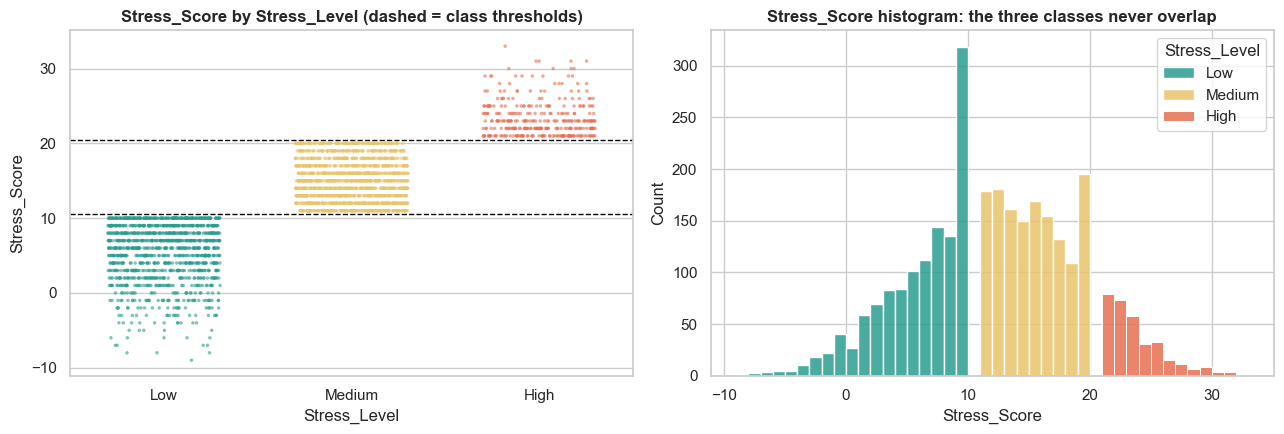

In [6]:
# Visual proof: score distribution per class with the class boundaries
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.stripplot(data=df, x="Stress_Level", y="Stress_Score", order=CLASS_ORDER, palette=CLASS_COLORS,
              size=2.5, alpha=0.6, jitter=0.3, ax=ax[0], hue="Stress_Level", legend=False)
for t in (10.5, 20.5):
    ax[0].axhline(t, color="black", ls="--", lw=1)
ax[0].set_title("Stress_Score by Stress_Level (dashed = class thresholds)")

for lvl in CLASS_ORDER:
    sns.histplot(df.loc[df["Stress_Level"] == lvl, "Stress_Score"], binwidth=1, color=CLASS_COLORS[lvl],
                 label=lvl, ax=ax[1], alpha=0.85)
ax[1].set_title("Stress_Score histogram: the three classes never overlap")
ax[1].legend(title="Stress_Level")
plt.tight_layout()
save_fig("00_leakage_stress_score_vs_level")

**Leakage conclusion.** The class ranges are completely disjoint and a fixed threshold rule (Low $\le$ 10, Medium 11-20, High $\ge$ 21) reproduces the label exactly. A model trained with `Stress_Score` would reach a near-perfect score simply because the label is a *re-coding* of that column - not because it learned anything about students. Such a result would be meaningless and misleading to the stakeholder, who has no `Stress_Score` for a new student. We therefore **drop `Stress_Score`** (leak) and **`Timestamp`** (an identifier with no causal relation to stress; the timestamps are also evenly spaced, see Section 4), and keep the 15 genuine predictors.

In [7]:
# Final selected dataset used for all following steps
df_full = df.copy()                                          # keep the original (with leak) only for reference
df = df.drop(columns=["Stress_Score", "Timestamp"])
print("Selected dataset:", df.shape, "-> 15 predictors + 1 target")
print("Predictors:", [c for c in df.columns if c != "Stress_Level"])

Selected dataset: (3000, 17) -> 15 predictors + 1 target
Predictors: ['Age', 'Gender', 'Study_Hours', 'Class_Attendance', 'Tuition', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Physical_Exercise', 'Social_Media_Use', 'Screen_Time', 'Family_Income_Level', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'University_Type']


# 4. KDD Step 2 - Preprocessing
We audit data quality before modelling: data types, missing values, duplicates, domain validity (are values possible?), outliers and categorical consistency.

In [8]:
# 4.1 Data types and basic info
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "example": df.iloc[0]}))

# 4.2 Missing values and duplicates
print("Missing values per column (total =", int(df.isna().sum().sum()), ")")
print("Empty/blank strings:", int((df.select_dtypes("object").apply(lambda s: s.str.strip() == "")).sum().sum()))
print("Fully duplicated rows (selected columns):", int(df.duplicated().sum()))
print("Fully duplicated rows (raw, incl. Timestamp):", int(df_full.duplicated().sum()))

,dtype,n_unique,example
Age,int64,6,24
Gender,object,2,Male
Study_Hours,int64,10,9
Class_Attendance,int64,60,71
Tuition,object,2,No
Exam_Frequency,int64,9,7
Assignment_Load,int64,9,4
Sleep_Hours,int64,6,6
Physical_Exercise,object,2,Yes
Social_Media_Use,int64,8,6


Missing values per column (total = 0 )
Empty/blank strings: 0
Fully duplicated rows (selected columns): 0
Fully duplicated rows (raw, incl. Timestamp): 0


In [9]:
# 4.3 Domain validity: values must be physically / logically possible for each variable
# (expected_min, expected_max) come from the questionnaire definition and common sense
domain_rules = {
    "Age": (19, 24), "Study_Hours": (0, 24), "Class_Attendance": (0, 100), "Exam_Frequency": (1, 20),
    "Assignment_Load": (1, 9), "Sleep_Hours": (0, 24), "Social_Media_Use": (0, 24), "Screen_Time": (0, 24),
    "Peer_Pressure": (1, 9), "Family_Support": (1, 9), "Anxiety_Level": (1, 9),
}
rows = []
for col, (lo, hi) in domain_rules.items():
    bad = int(((df[col] < lo) | (df[col] > hi)).sum())
    rows.append([col, lo, hi, df[col].min(), df[col].max(), bad])
domain_check = pd.DataFrame(rows, columns=["feature", "allowed_min", "allowed_max", "observed_min", "observed_max", "violations"])
display(domain_check)

# Cross-field logic checks
print("Social_Media_Use > Screen_Time (social media is part of screen time):",
      int((df["Social_Media_Use"] > df["Screen_Time"]).sum()), "rows")
print("Study + Sleep + Screen hours > 24:",
      int((df["Study_Hours"] + df["Sleep_Hours"] + df["Screen_Time"] > 24).sum()), "rows")

,feature,allowed_min,allowed_max,observed_min,observed_max,violations
0,Age,19,24,19,24,0
1,Study_Hours,0,24,0,9,0
2,Class_Attendance,0,100,40,99,0
3,Exam_Frequency,1,20,1,9,0
4,Assignment_Load,1,9,1,9,0
5,Sleep_Hours,0,24,4,9,0
6,Social_Media_Use,0,24,0,7,0
7,Screen_Time,0,24,1,11,0
8,Peer_Pressure,1,9,1,9,0
9,Family_Support,1,9,1,9,0


Social_Media_Use > Screen_Time (social media is part of screen time): 729 rows
Study + Sleep + Screen hours > 24: 152 rows


In [10]:
# 4.4 Outlier report with the IQR rule (Tukey fences: Q1 - 1.5*IQR, Q3 + 1.5*IQR)
num_cols_all = list(domain_rules.keys())
out_rows = []
for c in num_cols_all:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    out_rows.append([c, q1, q3, iqr, lo, hi, n_out, n_out / len(df) * 100])
outlier_report = pd.DataFrame(out_rows, columns=["feature", "Q1", "Q3", "IQR", "lower_fence", "upper_fence", "n_outliers", "pct_outliers"])
display(outlier_report.round(2))
print("Total flagged values:", int(outlier_report["n_outliers"].sum()))

,feature,Q1,Q3,IQR,lower_fence,upper_fence,n_outliers,pct_outliers
0,Age,20.0,23.0,3.0,15.5,27.5,0,0.0
1,Study_Hours,2.0,7.0,5.0,-5.5,14.5,0,0.0
2,Class_Attendance,54.0,84.0,30.0,9.0,129.0,0,0.0
3,Exam_Frequency,3.0,7.0,4.0,-3.0,13.0,0,0.0
4,Assignment_Load,3.0,7.0,4.0,-3.0,13.0,0,0.0
5,Sleep_Hours,5.0,8.0,3.0,0.5,12.5,0,0.0
6,Social_Media_Use,2.0,5.0,3.0,-2.5,9.5,0,0.0
7,Screen_Time,3.0,9.0,6.0,-6.0,18.0,0,0.0
8,Peer_Pressure,3.0,7.0,4.0,-3.0,13.0,0,0.0
9,Family_Support,3.0,7.0,4.0,-3.0,13.0,0,0.0


Total flagged values: 0


In [11]:
# 4.5 Categorical consistency: whitespace, case variants, unexpected labels
cat_cols = ["Gender", "Tuition", "Physical_Exercise", "Family_Income_Level", "University_Type", "Stress_Level"]
for c in cat_cols:
    cleaned = df[c].astype(str).str.strip()
    changed = int((cleaned != df[c]).sum())
    df[c] = cleaned                                   # strip stray whitespace (no-op if already clean)
    print(f"{c:<22} -> {dict(df[c].value_counts())}   (values changed by strip: {changed})")

# 4.6 Timestamp pattern (used only to judge data provenance, then dropped)
ts = pd.to_datetime(df_full["Timestamp"].str.replace(" GMT+6", "", regex=False), format="%Y/%m/%d %I:%M:%S %p")
gaps = ts.diff().dropna().dt.total_seconds()
print(f"\nTimestamps: {ts.min()} -> {ts.max()};  gap between consecutive submissions: "
      f"min {gaps.min():.0f}s, max {gaps.max():.0f}s, std {gaps.std():.1f}s")

Gender                 -> {'Female': np.int64(1538), 'Male': np.int64(1462)}   (values changed by strip: 0)
Tuition                -> {'No': np.int64(1545), 'Yes': np.int64(1455)}   (values changed by strip: 0)
Physical_Exercise      -> {'No': np.int64(1551), 'Yes': np.int64(1449)}   (values changed by strip: 0)
Family_Income_Level    -> {'Medium': np.int64(1333), 'Low': np.int64(1059), 'High': np.int64(608)}   (values changed by strip: 0)
University_Type        -> {'Public University': np.int64(1003), 'National University': np.int64(1000), 'Private University': np.int64(997)}   (values changed by strip: 0)
Stress_Level           -> {'Medium': np.int64(1431), 'Low': np.int64(1243), 'High': np.int64(326)}   (values changed by strip: 0)

Timestamps: 2025-10-01 00:00:00 -> 2025-12-15 23:22:31;  gap between consecutive submissions: min 2188s, max 2189s, std 0.4s


**Data-quality findings and decisions**

* **Completeness and uniqueness:** no missing values, no blank strings and no duplicated rows (with or without the timestamp), so no imputation or de-duplication is needed.
* **Domain validity:** every numeric answer lies inside its allowed range (attendance 40-99%, 1-9 scales stay within 1-9, hours within 0-24); there are zero violations.
* **Outliers:** the IQR rule flags **0 values** in every feature. Even if it had flagged some, they would be valid survey answers on bounded scales (a 9 on a 1-9 scale), not measurement errors, so we would keep them - removing them would delete exactly the extreme (e.g. highly stressed) students we most want to detect. No outlier treatment is applied.
* **Categorical consistency:** all categorical columns have clean, consistent labels (no case variants or whitespace issues).
* **Logical inconsistencies (kept, flagged):** 729 students (24.3%) report more social-media hours than total screen hours, and 152 students (5.1%) have study + sleep + screen time above 24 hours. These are contradictions in self-reported answers. They cannot be repaired reliably, and deleting a quarter of the data would be costly, so we keep them and list them as a data-quality limitation.
* **`Physical_Exercise`:** the question asked for *hours per week* but the column only contains Yes/No, so it is treated as a binary feature and the lost intensity information is noted as a limitation.
* **Provenance warning:** consecutive timestamps are separated by a constant interval (2188-2189 seconds, about 36.5 minutes, for all 3,000 rows) - real respondents do not submit forms on a metronome. Together with the near-uniform feature distributions seen later, this strongly suggests the dataset is synthetic (generated), which matters for how the results can be interpreted (Section 9).

# 5. Exploratory Data Analysis (EDA)
EDA is done on the **full cleaned dataset** to understand the data; no modelling decisions that touch the test set are made here (the split happens in Section 6, and every learned transformation is fitted on training data only).

## 5.1 Target distribution

,count,percent
Stress_Level,,
Low,1243,41.43
Medium,1431,47.70
High,326,10.87


Imbalance ratio (largest / smallest class): 4.39


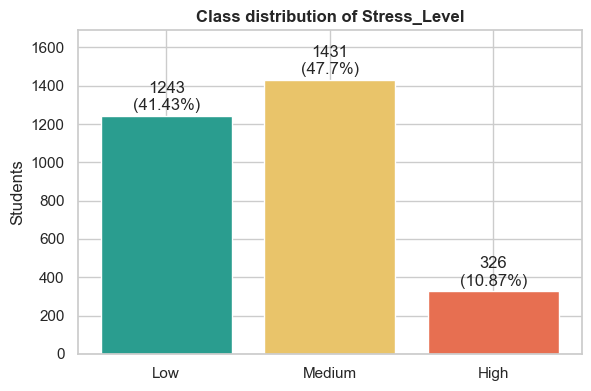

In [12]:
# Target distribution: counts and percentages
target_counts = df["Stress_Level"].value_counts().reindex(CLASS_ORDER)
target_pct = (target_counts / len(df) * 100).round(2)
display(pd.DataFrame({"count": target_counts, "percent": target_pct}))
print(f"Imbalance ratio (largest / smallest class): {target_counts.max() / target_counts.min():.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(CLASS_ORDER, target_counts.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER])
for b, n, p in zip(bars, target_counts.values, target_pct.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 15, f"{n}\n({p}%)", ha="center", va="bottom")
ax.set_ylim(0, target_counts.max() * 1.18)
ax.set_title("Class distribution of Stress_Level"); ax.set_ylabel("Students")
save_fig("01_class_distribution")

**Observations**

The target is **imbalanced**: Medium is the largest class (47.7%), Low is 41.4% and **High is only 10.9% (326 students)**, a 4.4:1 ratio between the largest and smallest class. Consequences: (1) accuracy alone is misleading, so Macro F1 is the primary metric; (2) the split must be stratified; (3) imbalance-handling options (`class_weight`, sample weights, NB priors) are included in tuning.

## 5.2 Numeric features by stress level

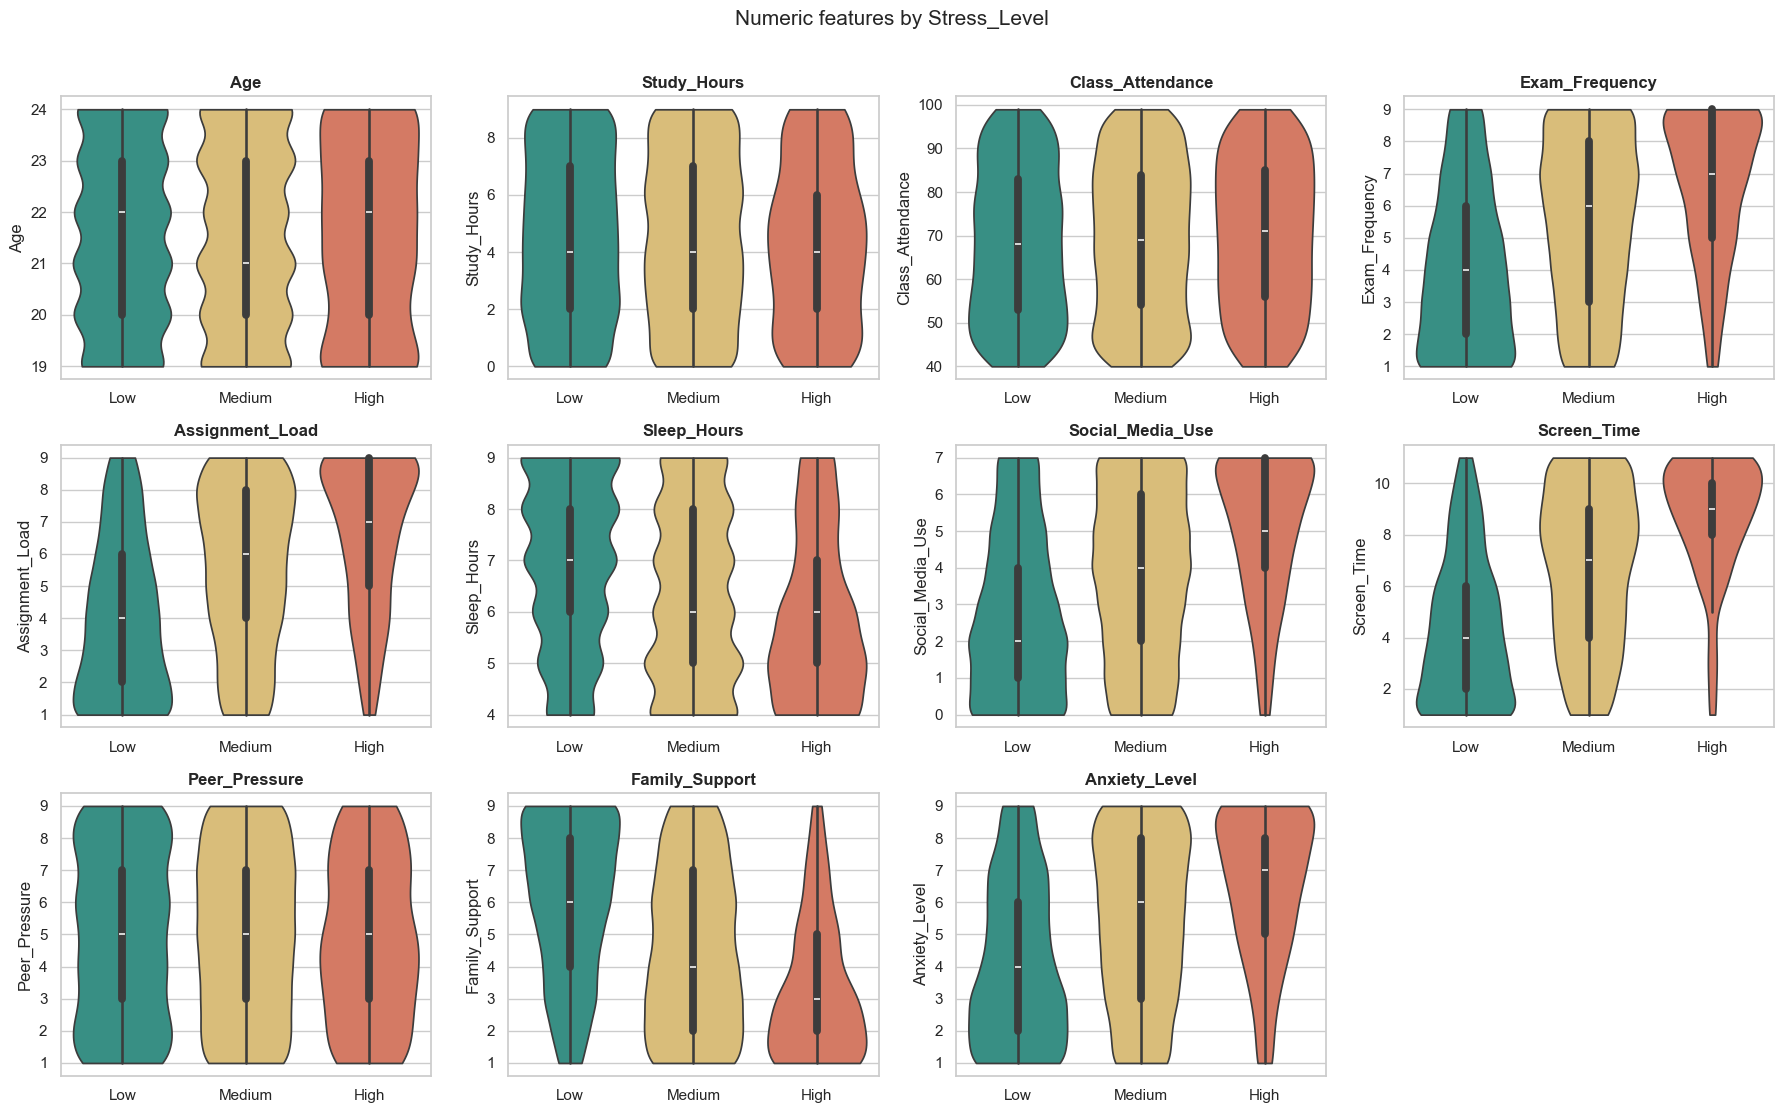

Stress_Level,Low,Medium,High
Age,21.52,21.51,21.51
Study_Hours,4.51,4.52,4.29
Class_Attendance,68.29,69.08,70.19
Exam_Frequency,4.12,5.45,6.64
Assignment_Load,4.02,5.49,6.55
Sleep_Hours,6.90,6.34,5.88
Social_Media_Use,2.79,3.75,5.01
Screen_Time,4.37,6.64,8.65
Peer_Pressure,5.00,5.01,4.83
Family_Support,5.99,4.58,3.31


In [13]:
# Distribution of every numeric feature per stress level (violin + inner box) in a grid
num_features = ["Age", "Study_Hours", "Class_Attendance", "Exam_Frequency", "Assignment_Load", "Sleep_Hours",
                "Social_Media_Use", "Screen_Time", "Peer_Pressure", "Family_Support", "Anxiety_Level"]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), num_features):
    sns.violinplot(data=df, x="Stress_Level", y=col, order=CLASS_ORDER, palette=CLASS_COLORS, hue="Stress_Level",
                   legend=False, inner="box", cut=0, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
for ax in axes.ravel()[len(num_features):]:
    ax.axis("off")
fig.suptitle("Numeric features by Stress_Level", fontsize=15, y=1.01)
plt.tight_layout()
save_fig("02_numeric_features_by_stress")

# Group means - an easier numeric view of the same picture
display(df.groupby("Stress_Level")[num_features].mean().reindex(CLASS_ORDER).T.round(2))

**Observations**

* **Strong separation** between stress levels is visible for **Screen_Time** (class means 4.4 / 6.6 / 8.7 hours for Low / Medium / High), **Social_Media_Use** (2.8 / 3.8 / 5.0), **Exam_Frequency** (4.1 / 5.5 / 6.6), **Assignment_Load** (4.0 / 5.5 / 6.6) and **Anxiety_Level** (4.2 / 5.4 / 6.5): higher values go with higher stress.
* **Family_Support** (6.0 / 4.6 / 3.3) and **Sleep_Hours** (6.9 / 6.3 / 5.9) move in the opposite direction: they look *protective*.
* **Age, Study_Hours, Class_Attendance and Peer_Pressure** have almost identical distributions in the three groups (e.g. mean age 21.5 in every group), so they carry little or no signal on their own. It is notable that Peer_Pressure - often cited as a stressor - shows no relationship here.
* Most features are close to uniformly distributed over their range, which is unusual for real survey data (another hint of synthetic generation).

## 5.3 Categorical features by stress level

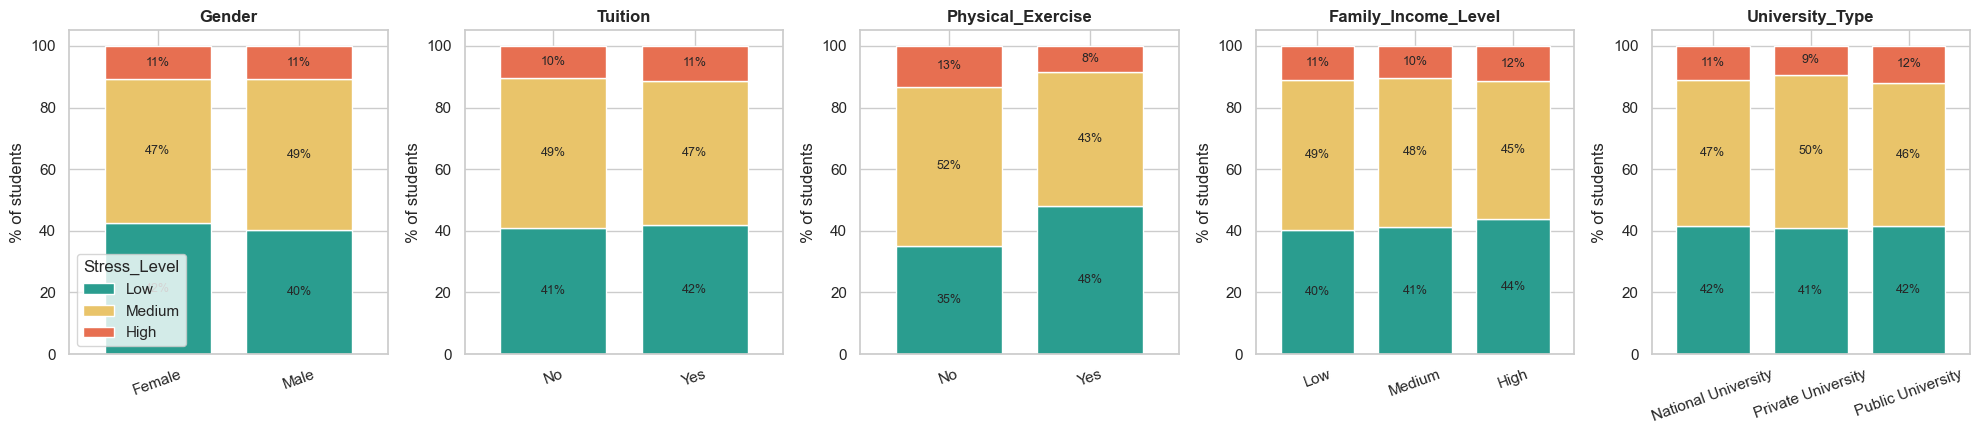

In [14]:
# Stacked 100% bars: share of Low/Medium/High inside each category value
cat_features = ["Gender", "Tuition", "Physical_Exercise", "Family_Income_Level", "University_Type"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, cat_features):
    order = ["Low", "Medium", "High"] if col == "Family_Income_Level" else sorted(df[col].unique())
    ct = pd.crosstab(df[col], df["Stress_Level"], normalize="index").reindex(index=order, columns=CLASS_ORDER) * 100
    ct.plot(kind="bar", stacked=True, color=[CLASS_COLORS[c] for c in CLASS_ORDER], ax=ax, width=0.75, legend=False)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.0f%%", label_type="center", fontsize=9)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("% of students"); ax.tick_params(axis="x", rotation=20)
axes[0].legend(CLASS_ORDER, title="Stress_Level", loc="lower left")
plt.tight_layout()
save_fig("03_categorical_vs_stress")

**Observations**

Within each category the Low/Medium/High shares are very similar for Gender, Tuition, Family_Income_Level and University_Type, i.e. these demographic attributes do not visibly change the stress profile. **Physical_Exercise** is the exception: students answering "Yes" have a different (lower) stress profile than those answering "No". The formal tests in 5.5 confirm this.

## 5.4 Correlation analysis
The target is ordinal (Low < Medium < High), so we encode it as 0/1/2 and use **Spearman** rank correlation, which is appropriate for ordinal 1-9 scales and does not assume linearity.

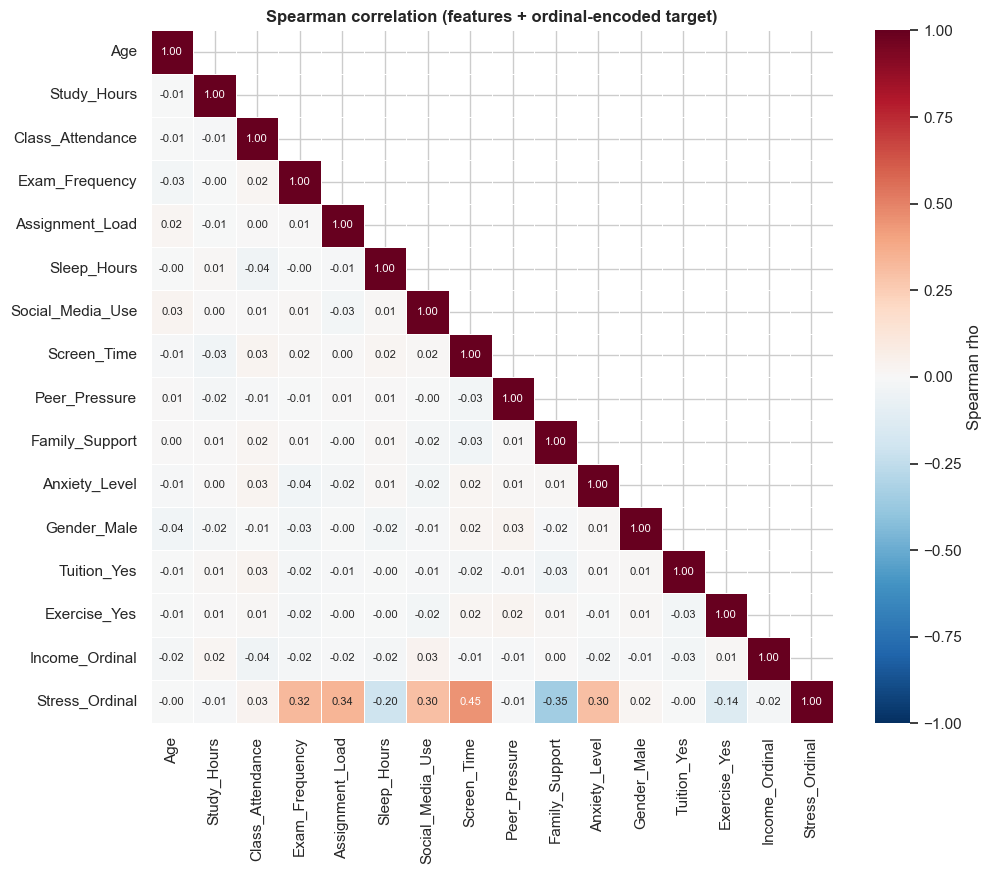

,rho_with_stress
Screen_Time,0.447
Family_Support,-0.347
Assignment_Load,0.339
Exam_Frequency,0.323
Anxiety_Level,0.298
Social_Media_Use,0.297
Sleep_Hours,-0.204
Exercise_Yes,-0.138
Class_Attendance,0.033
Income_Ordinal,-0.020


Strongest feature-feature correlations:


,f1,f2,rho
38,Class_Attendance,Income_Ordinal,-0.042
29,Class_Attendance,Sleep_Hours,-0.041
10,Age,Gender_Male,-0.038
45,Exam_Frequency,Anxiety_Level,-0.037
78,Screen_Time,Family_Support,-0.035


In [15]:
# Build an analysis frame: numeric features + binary/ordinal encodings + ordinal target
eda = df.copy()
eda["Gender_Male"] = (eda["Gender"] == "Male").astype(int)
eda["Tuition_Yes"] = (eda["Tuition"] == "Yes").astype(int)
eda["Exercise_Yes"] = (eda["Physical_Exercise"] == "Yes").astype(int)
eda["Income_Ordinal"] = eda["Family_Income_Level"].map({"Low": 0, "Medium": 1, "High": 2})
eda["Stress_Ordinal"] = eda["Stress_Level"].map({"Low": 0, "Medium": 1, "High": 2})
corr_cols = num_features + ["Gender_Male", "Tuition_Yes", "Exercise_Yes", "Income_Ordinal", "Stress_Ordinal"]
corr = eda[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, linewidths=0.4, cbar_kws={"label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlation (features + ordinal-encoded target)")
save_fig("04_correlation_heatmap")

# Ranked correlation with the target
display(corr["Stress_Ordinal"].drop("Stress_Ordinal").sort_values(key=np.abs, ascending=False).round(3).to_frame("rho_with_stress"))

# Multicollinearity check: strongest feature-feature correlations
cf = corr.drop(index="Stress_Ordinal", columns="Stress_Ordinal")
pairs = cf.where(np.triu(np.ones(cf.shape, dtype=bool), k=1)).stack().reset_index()
pairs.columns = ["f1", "f2", "rho"]
pairs["abs"] = pairs["rho"].abs()
print("Strongest feature-feature correlations:")
display(pairs.sort_values("abs", ascending=False).head(5)[["f1", "f2", "rho"]].round(3))

**Observations**

* Strongest correlations with the ordinal stress level (Spearman): **Screen_Time (+0.45)**, **Family_Support (-0.35)**, **Assignment_Load (+0.34)**, **Exam_Frequency (+0.32)**, **Anxiety_Level (+0.30)**, **Social_Media_Use (+0.30)**, then **Sleep_Hours (-0.20)** and **Exercise (-0.14)**. All other features have |rho| below 0.04.
* The features are essentially **uncorrelated with each other** (largest feature-feature |rho| about 0.04), so there is no multicollinearity problem and each feature adds independent information; this is also unusual for real survey data.
* The correlations are moderate individually; stress seems to be driven by the *accumulation* of several factors rather than any single one, which motivates multivariate models.

## 5.5 Statistical association tests
Correlations describe direction; formal tests tell us whether the differences between stress groups could be due to chance.
* **Numeric feature vs Stress_Level:** Kruskal-Wallis H test (non-parametric ANOVA, suitable for ordinal/discrete data); effect size $\varepsilon^2 = \dfrac{H-k+1}{n-k}$ ($k$ = 3 groups).
* **Categorical feature vs Stress_Level:** chi-square test of independence; effect size **Cramér's V** $=\sqrt{\chi^2 / (n\,(\min(r,c)-1))}$.
* Because we run many tests, the p-values are compared with a Bonferroni-adjusted threshold $\alpha/m$.

Bonferroni-adjusted alpha = 0.05/16 = 0.0031


,feature,test,statistic,p_value,effect_size,significant (Bonferroni)
0,Screen_Time,Kruskal-Wallis,604.3,6.05e-132,0.201,True
1,Physical_Exercise,Chi-square,57.5,3.25e-13,0.138,True
2,Family_Support,Kruskal-Wallis,363.6,1.10e-79,0.121,True
3,Assignment_Load,Kruskal-Wallis,345.5,9.50e-76,0.115,True
4,Exam_Frequency,Kruskal-Wallis,315.6,2.89e-69,0.105,True
5,Social_Media_Use,Kruskal-Wallis,278.6,3.17e-61,0.092,True
6,Anxiety_Level,Kruskal-Wallis,267.4,8.59e-59,0.089,True
7,Sleep_Hours,Kruskal-Wallis,125.9,4.66e-28,0.041,True
8,University_Type,Chi-square,4.5,3.45e-01,0.027,False
9,Family_Income_Level,Chi-square,3.2,5.33e-01,0.023,False


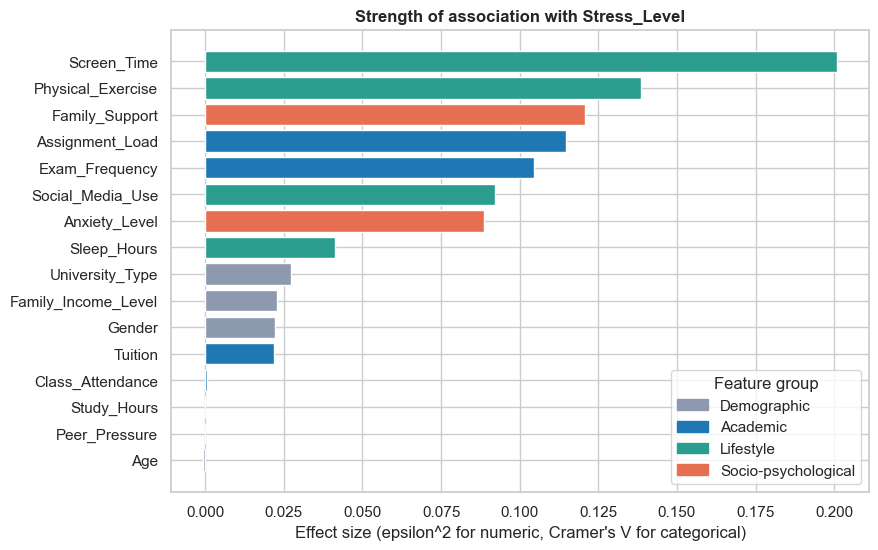

In [16]:
# Kruskal-Wallis for numeric features
n = len(df); k = 3
kw_rows = []
for col in num_features:
    groups = [df.loc[df["Stress_Level"] == lvl, col] for lvl in CLASS_ORDER]
    H, p = stats.kruskal(*groups)
    kw_rows.append([col, "Kruskal-Wallis", H, p, (H - k + 1) / (n - k)])

# Chi-square + Cramer's V for categorical features
def cramers_v(confusion):
    """Cramer's V effect size from a contingency table (0 = independent, 1 = perfectly associated)."""
    chi2 = stats.chi2_contingency(confusion, correction=False)[0]
    r, c = confusion.shape
    return np.sqrt(chi2 / (confusion.to_numpy().sum() * (min(r, c) - 1)))

for col in cat_features:
    ct = pd.crosstab(df[col], df["Stress_Level"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    kw_rows.append([col, "Chi-square", chi2, p, cramers_v(ct)])

tests = pd.DataFrame(kw_rows, columns=["feature", "test", "statistic", "p_value", "effect_size"])
alpha_adj = 0.05 / len(tests)
tests["significant (Bonferroni)"] = tests["p_value"] < alpha_adj
tests = tests.sort_values("effect_size", ascending=False).reset_index(drop=True)
print(f"Bonferroni-adjusted alpha = 0.05/{len(tests)} = {alpha_adj:.4f}")
display(tests.style.format({"statistic": "{:.1f}", "p_value": "{:.2e}", "effect_size": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 6))
colors = [GROUP_COLORS[FEATURE_GROUP[f]] for f in tests["feature"]]
ax.barh(tests["feature"][::-1], tests["effect_size"][::-1], color=colors[::-1])
ax.set_xlabel("Effect size (epsilon^2 for numeric, Cramer's V for categorical)")
ax.set_title("Strength of association with Stress_Level")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax.legend(handles, GROUP_COLORS.keys(), title="Feature group", loc="lower right")
save_fig("05_association_effect_sizes")

**Observations**

* **Eight features are statistically significant** even after Bonferroni correction (alpha = 0.0031): Screen_Time, Physical_Exercise, Family_Support, Assignment_Load, Exam_Frequency, Social_Media_Use, Anxiety_Level and Sleep_Hours (p-values far below 1e-25). Effect sizes are small-to-moderate individually (epsilon-squared 0.04-0.20, Cramer's V 0.14 for exercise); Screen_Time is the strongest.
* **Eight features are not significant** (p between 0.18 and 0.99, effect sizes about 0): University_Type, Family_Income_Level, Gender, Tuition, Class_Attendance, Study_Hours, Peer_Pressure and Age. No demographic attribute is related to stress in this dataset.
* This agrees with the correlation analysis and tells us what to expect from the models: only the eight significant features should matter.

# 6. KDD Step 3 - Transformation

## 6.1 Encoding and scaling plan
| Feature type | Columns | Treatment | Reason |
|---|---|---|---|
| Numeric / 1-9 scales | Age, Study_Hours, Class_Attendance, Exam_Frequency, Assignment_Load, Sleep_Hours, Social_Media_Use, Screen_Time, Peer_Pressure, Family_Support, Anxiety_Level | `StandardScaler` | SVM (distance/margin based) and Naive Bayes (Gaussian likelihood) are sensitive to feature scale; trees are not, but scaling does no harm |
| Binary | Gender, Tuition, Physical_Exercise | map to 0/1 (`OrdinalEncoder` with explicit categories) | only two values |
| Ordinal | Family_Income_Level | Low=0, Medium=1, High=2 | order carries meaning |
| Nominal | University_Type | One-hot encoding | no natural order; avoids inventing a fake ranking |
| Target | Stress_Level | Low=0, Medium=1, High=2 | ordinal classes; index 2 = High is used in the High-recall metrics |

Everything is wrapped in a **`ColumnTransformer` inside a `Pipeline`** together with the classifier. During cross-validation, the scaler/encoders are then re-fitted on each *training fold only*, so no information from validation folds (or the test set) leaks into preprocessing.

**Why scaling matters for some models only.** SVM computes distances/dot products, so a feature measured in the range 40-99 (attendance %) would dominate one measured in 1-9. Gaussian NB estimates a mean/variance per feature, which is scale-equivariant in principle but numerically better behaved after standardisation (and `var_smoothing` is defined relative to variance). Decision trees, Random Forest and XGBoost split on thresholds, which are unaffected by monotonic rescaling, so they get the same result with or without scaling.

In [17]:
# Feature lists by treatment
NUMERIC_COLS = ["Age", "Study_Hours", "Class_Attendance", "Exam_Frequency", "Assignment_Load", "Sleep_Hours",
                "Social_Media_Use", "Screen_Time", "Peer_Pressure", "Family_Support", "Anxiety_Level"]
BINARY_COLS  = ["Gender", "Tuition", "Physical_Exercise"]
ORDINAL_COLS = ["Family_Income_Level"]
NOMINAL_COLS = ["University_Type"]
FEATURES = NUMERIC_COLS + BINARY_COLS + ORDINAL_COLS + NOMINAL_COLS

# Explicit category orders -> deterministic, documented encodings
binary_categories = [["Female", "Male"], ["No", "Yes"], ["No", "Yes"]]      # Male=1, Yes=1
income_categories = [["Low", "Medium", "High"]]

def make_preprocessor(scale_numeric=True):
    """Build the ColumnTransformer. scale_numeric=False is used only for the human-readable shallow tree."""
    return ColumnTransformer([
        ("num", StandardScaler() if scale_numeric else "passthrough", NUMERIC_COLS),
        ("bin", OrdinalEncoder(categories=binary_categories), BINARY_COLS),
        ("ord", OrdinalEncoder(categories=income_categories), ORDINAL_COLS),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL_COLS),
    ])

# Target encoding
TARGET_MAP = {"Low": 0, "Medium": 1, "High": 2}
HIGH = TARGET_MAP["High"]
X = df[FEATURES].copy()
y = df["Stress_Level"].map(TARGET_MAP).astype(int)
print("X:", X.shape, "| y:", y.shape, "| target map:", TARGET_MAP)

X:

 (3000, 16) | y: (3000,) | target map: {'Low': 0, 'Medium': 1, 'High': 2}


## 6.2 Stratified 80/20 train/test split
The test set (20%) is locked away and used **once**, for the final evaluation. `stratify=y` keeps the Low/Medium/High proportions identical in both parts, which matters most for the rare High class.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

inv = {v: k for k, v in TARGET_MAP.items()}
prop = pd.DataFrame({
    "full %":  y.map(inv).value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "train %": y_train.map(inv).value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "test %":  y_test.map(inv).value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "train n": y_train.map(inv).value_counts().reindex(CLASS_ORDER),
    "test n":  y_test.map(inv).value_counts().reindex(CLASS_ORDER),
}).round(2)
display(prop)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Peek at what the preprocessor produces (fitted on TRAIN only)
prep_demo = make_preprocessor().fit(X_train)
feat_names = [n.split("__", 1)[1] for n in prep_demo.get_feature_names_out()]
display(pd.DataFrame(prep_demo.transform(X_train.head(5)), columns=feat_names).round(2))
print(len(feat_names), "model input features after encoding:", feat_names)

,full %,train %,test %,train n,test n
Stress_Level,,,,,
Low,41.43,41.42,41.50,994,249
Medium,47.70,47.71,47.67,1145,286
High,10.87,10.88,10.83,261,65


Train: (2400, 16) | Test: (600, 16)


,Age,Study_Hours,Class_Attendance,Exam_Frequency,Assignment_Load,Sleep_Hours,Social_Media_Use,Screen_Time,Peer_Pressure,Family_Support,Anxiety_Level,Gender,Tuition,Physical_Exercise,Family_Income_Level,University_Type_National University,University_Type_Private University,University_Type_Public University
0,0.28,0.18,-0.22,-0.80,0.80,-0.30,1.10,0.95,-1.17,-0.01,0.77,1.0,1.0,0.0,1.0,1.0,0.0,0.0
1,0.28,1.23,-0.04,-0.41,-0.75,0.88,-1.08,-0.30,-1.17,1.15,1.54,0.0,0.0,0.0,2.0,0.0,1.0,0.0
2,0.28,-1.23,-0.96,-1.57,-1.53,-0.90,0.23,-1.24,0.77,-0.01,0.38,0.0,1.0,0.0,1.0,1.0,0.0,0.0
3,0.28,0.18,-1.43,-0.02,1.58,0.29,-1.52,0.95,-0.39,-0.40,0.77,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,-1.47,-0.52,0.88,-0.80,0.41,-1.49,-1.52,0.95,0.77,0.76,1.54,1.0,1.0,0.0,2.0,0.0,0.0,1.0


18 model input features after encoding: ['Age', 'Study_Hours', 'Class_Attendance', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'Gender', 'Tuition', 'Physical_Exercise', 'Family_Income_Level', 'University_Type_National University', 'University_Type_Private University', 'University_Type_Public University']


Class proportions are preserved to within rounding across train and test, so test-set metrics are representative of the training distribution.

# 7. KDD Step 4 - Data Mining

## 7.1 Experimental design
1. **Baseline reference:** a `DummyClassifier(strategy="most_frequent")` shows the score of "always predict Medium". Any useful model must clearly beat it on Macro F1.
2. **Baseline models:** the five classifiers with near-default parameters, evaluated by 5-fold stratified cross-validation on the **training set only**. Metrics: Macro F1 (primary), accuracy and High-stress recall (custom scorer).
3. **Hyperparameter tuning:** `GridSearchCV` with `scoring` focused on **Macro F1** (`refit="f1_macro"`), 5-fold stratified CV, modest grids to keep the runtime reasonable.
4. **Class imbalance (High is about 11%):** `class_weight="balanced"` is a tunable option for Decision Tree, Random Forest and SVM; XGBoost has no such argument for multi-class, so we pass `sample_weight=compute_sample_weight("balanced", y_train)`; Gaussian NB has no weighting, but we tune its class **priors** (empirical vs uniform), which is the NB equivalent of re-balancing.
5. Final evaluation of the tuned models on the untouched **test set** (Section 8).

In [19]:
# Cross-validation splitter shared by every experiment (same folds => fair comparison)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Scorers: Macro F1 (primary), accuracy, and recall / precision of the High class only
high_recall_scorer = make_scorer(recall_score, labels=[HIGH], average="macro", zero_division=0)
scoring = {"f1_macro": "f1_macro", "accuracy": "accuracy", "high_recall": high_recall_scorer}

def make_pipe(clf, scale=True):
    """Preprocessing + classifier in ONE pipeline so CV re-fits the encoders/scaler per training fold."""
    return Pipeline([("prep", make_preprocessor(scale)), ("clf", clf)])

# Balanced sample weights for XGBoost (computed on TRAIN labels only)
sw_train = compute_sample_weight("balanced", y_train)

# --- Baseline (default-ish) models ---------------------------------------------------------
baseline_models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
    "Naive Bayes":   GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM":           SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "XGBoost":       XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                                   random_state=RANDOM_STATE, n_jobs=1),
}
MODEL_NAMES = list(baseline_models.keys())

## 7.2 Dummy baseline and baseline models (5-fold CV on the training set)

In [20]:
def cv_summary(pipe, name, fit_params=None):
    """Run stratified 5-fold CV and return mean/std of each scorer as a flat dict."""
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, params=fit_params, n_jobs=-1)
    out = {"model": name}
    for m in scoring:
        out[f"{m}_mean"] = res[f"test_{m}"].mean()
        out[f"{m}_std"]  = res[f"test_{m}"].std()
    return out

t0 = time.time()
baseline_rows = [cv_summary(make_pipe(DummyClassifier(strategy="most_frequent")), "Dummy")]
for name, clf in baseline_models.items():
    baseline_rows.append(cv_summary(make_pipe(clf), name))
baseline_cv = pd.DataFrame(baseline_rows).set_index("model")
print(f"Baseline CV finished in {time.time() - t0:.1f}s")
display(baseline_cv.round(4))

Baseline CV finished in 2.9s


,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,high_recall_mean,high_recall_std
model,,,,,,
Dummy,0.2153,0.0000,0.4771,0.0000,0.0000,0.0000
Random Forest,0.7290,0.0198,0.8321,0.0111,0.3025,0.0450
Naive Bayes,0.7284,0.0164,0.8542,0.0080,0.2528,0.0303
Decision Tree,0.6870,0.0345,0.7200,0.0273,0.5821,0.0626
SVM,0.9139,0.0140,0.9317,0.0062,0.7814,0.0558
XGBoost,0.8311,0.0067,0.8717,0.0063,0.6054,0.0285


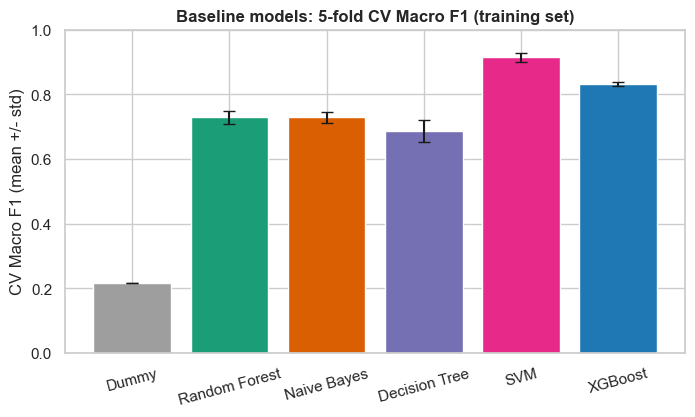

In [21]:
# Visual: baseline CV macro F1 with std error bars
fig, ax = plt.subplots(figsize=(8, 4.2))
order = baseline_cv.index.tolist()
ax.bar(order, baseline_cv["f1_macro_mean"], yerr=baseline_cv["f1_macro_std"], capsize=4,
       color=[MODEL_COLORS[m] for m in order])
ax.set_ylabel("CV Macro F1 (mean +/- std)"); ax.set_ylim(0, 1)
ax.set_title("Baseline models: 5-fold CV Macro F1 (training set)")
plt.xticks(rotation=15)
save_fig("06_baseline_cv_macro_f1")

**Observations**

* All five models beat the Dummy reference (CV Macro F1 0.215) by a wide margin.
* Without any imbalance handling, **High-stress recall is poor for most baselines**: Naive Bayes 0.25, Random Forest 0.30, Decision Tree 0.58, XGBoost 0.61, SVM 0.78. These models favour the big classes, exactly the risk described in Section 2.3. Accuracy hides this (e.g. Naive Bayes has accuracy 0.85 but only 25% High recall).
* The **RBF SVM is already the strongest baseline** (CV Macro F1 0.914), followed by XGBoost (0.831); Random Forest and Naive Bayes are close to each other (about 0.73) and the unconstrained Decision Tree is last (0.687, with the largest fold-to-fold variation).

## 7.3 Hyperparameter tuning with GridSearchCV
The grids are deliberately modest: they cover the parameters that control model complexity (depth, leaf size, `C`, `gamma`, learning rate...) plus the imbalance options described above. Scoring uses **Macro F1** to select the best configuration; accuracy and High recall are tracked in the same CV run for context.

In [22]:
# Search spaces (parameter names are prefixed with clf__ because the classifier lives inside the Pipeline)
tuning = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10, 20],
         "clf__min_samples_leaf": [1, 3, 5], "clf__class_weight": [None, "balanced_subsample"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": np.logspace(-9, -1, 5), "clf__priors": [None, [1/3, 1/3, 1/3]]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [3, 5, 7, 10, None],
         "clf__min_samples_leaf": [1, 5, 10, 20], "clf__class_weight": [None, "balanced"]}),
    "SVM": (
        SVC(probability=True, random_state=RANDOM_STATE),
        [{"clf__kernel": ["rbf"], "clf__C": [0.5, 1, 5, 20], "clf__gamma": ["scale", 0.01, 0.05],
          "clf__class_weight": [None, "balanced"]},
         {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10], "clf__class_weight": [None, "balanced"]}]),
    "XGBoost": (
        XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                      random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1],
         "clf__subsample": [0.8, 1.0]}),
}
# Extra fit parameters per model: XGBoost receives balanced sample weights
fit_kwargs = {name: ({"clf__sample_weight": sw_train} if name == "XGBoost" else {}) for name in MODEL_NAMES}

grid_searches, tune_times = {}, {}
for name, (clf, grid) in tuning.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), param_grid=grid, scoring=scoring, refit="f1_macro", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train, **fit_kwargs[name])
    grid_searches[name] = gs
    tune_times[name] = time.time() - t0
    n_cand = len(gs.cv_results_["params"])
    print(f"{name:<14} {n_cand:>3} candidates | best CV macro F1 = {gs.best_score_:.4f} | {tune_times[name]:.0f}s")
print(f"Total tuning time: {sum(tune_times.values()) / 60:.1f} min")

Random Forest   36 candidates | best CV macro F1 = 0.8258 | 12s
Naive Bayes     10 candidates | best CV macro F1 = 0.8469 | 0s


Decision Tree   80 candidates | best CV macro F1 = 0.7135 | 1s


SVM             30 candidates | best CV macro F1 = 1.0000 | 4s


XGBoost         16 candidates | best CV macro F1 = 0.8925 | 1s
Total tuning time: 0.3 min


In [23]:
# Collect best params and the CV metrics (mean +/- std) of the best candidate of each model
best_params, tuned_rows = {}, []
for name, gs in grid_searches.items():
    i = gs.best_index_
    best_params[name] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    row = {"model": name}
    for m in scoring:
        row[f"{m}_mean"] = gs.cv_results_[f"mean_test_{m}"][i]
        row[f"{m}_std"]  = gs.cv_results_[f"std_test_{m}"][i]
    tuned_rows.append(row)
tuned_cv = pd.DataFrame(tuned_rows).set_index("model")

print("Best hyper-parameters:")
for name, p in best_params.items():
    print(f"  {name:<14}: {p}")

# Baseline vs tuned comparison (Macro F1 and High recall)
cmp_cv = pd.DataFrame({
    "baseline F1 mean": baseline_cv.loc[MODEL_NAMES, "f1_macro_mean"],
    "tuned F1 mean":    tuned_cv["f1_macro_mean"],
    "tuned F1 std":     tuned_cv["f1_macro_std"],
    "baseline High recall": baseline_cv.loc[MODEL_NAMES, "high_recall_mean"],
    "tuned High recall":    tuned_cv["high_recall_mean"],
})
cmp_cv["F1 gain"] = cmp_cv["tuned F1 mean"] - cmp_cv["baseline F1 mean"]
display(cmp_cv.round(4))

# Save result artefacts
cv_out = pd.concat([baseline_cv.assign(stage="baseline"), tuned_cv.assign(stage="tuned")]).reset_index()
cv_out = cv_out[["model", "stage"] + [c for c in cv_out.columns if c not in ("model", "stage")]]
cv_out.round(5).to_csv("results/cv_results.csv", index=False)
with open("results/best_params.json", "w") as f:
    json.dump(best_params, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

Best hyper-parameters:
  Random Forest : {'class_weight': 'balanced_subsample', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 400}
  Naive Bayes   : {'priors': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333], 'var_smoothing': np.float64(0.1)}
  Decision Tree : {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1}
  SVM           : {'C': 10, 'class_weight': None, 'kernel': 'linear'}
  XGBoost       : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}


,baseline F1 mean,tuned F1 mean,tuned F1 std,baseline High recall,tuned High recall,F1 gain
model,,,,,,
Random Forest,0.7290,0.8258,0.0243,0.3025,0.6473,0.0968
Naive Bayes,0.7284,0.8469,0.0207,0.2528,0.9079,0.1184
Decision Tree,0.6870,0.7135,0.0144,0.5821,0.6284,0.0265
SVM,0.9139,1.0000,0.0000,0.7814,1.0000,0.0861
XGBoost,0.8311,0.8925,0.0178,0.6054,0.8658,0.0614


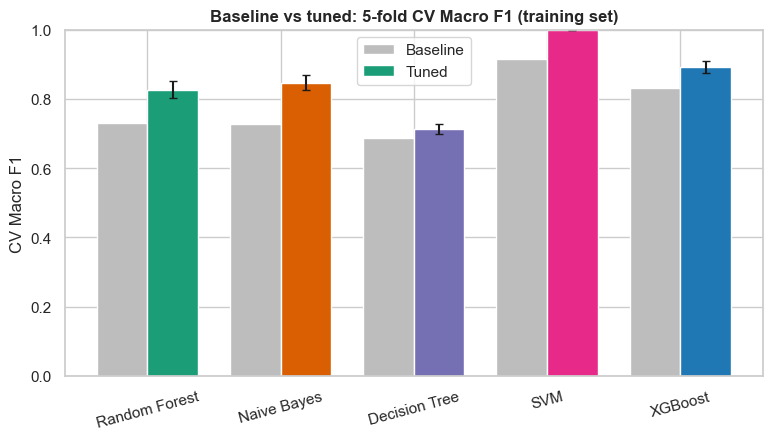

In [24]:
# Baseline vs tuned CV Macro F1, side by side
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(MODEL_NAMES)); w = 0.38
ax.bar(x - w/2, cmp_cv["baseline F1 mean"], w, label="Baseline", color="#bdbdbd")
ax.bar(x + w/2, cmp_cv["tuned F1 mean"], w, yerr=cmp_cv["tuned F1 std"], capsize=3, label="Tuned",
       color=[MODEL_COLORS[m] for m in MODEL_NAMES])
ax.set_xticks(x); ax.set_xticklabels(MODEL_NAMES, rotation=15); ax.set_ylabel("CV Macro F1")
ax.set_ylim(0, 1); ax.legend(); ax.set_title("Baseline vs tuned: 5-fold CV Macro F1 (training set)")
save_fig("07_baseline_vs_tuned_cv")

**Observations**

* Tuning improves Macro F1 for every model; the gains are largest for **Naive Bayes (+0.118)**, **Random Forest (+0.097)** and **SVM (+0.086)**, and **High recall improves dramatically** (Naive Bayes 0.25 to 0.91, Random Forest 0.30 to 0.65, XGBoost 0.61 to 0.87), showing that the imbalance options matter: balanced class weights / sample weights were chosen for RF, DT and XGBoost, and **uniform priors** for Naive Bayes.
* The SVM search selected the **linear kernel** (C = 10, no class weights) and reached a CV Macro F1 of **1.000 with zero variance across folds**. The linear kernel beating the RBF kernel is a first hint that the class boundary in this data is linear; Section 8.6.1 investigates this perfect score.
* The ranking after tuning (CV Macro F1): SVM 1.000 > XGBoost 0.893 > Naive Bayes 0.847 > Random Forest 0.826 > Decision Tree 0.714.
* Two caveats: the tuned CV scores are slightly optimistic because the same folds select and score the configuration, and Naive Bayes chose `var_smoothing = 0.1`, the edge of its grid, so a wider grid might help it slightly further. Neither changes the ranking by a meaningful margin.

# 8. KDD Step 5 - Interpretation and Evaluation
From here on the **test set is used once** to report final performance of the tuned models (already refit on the full training set by `GridSearchCV`).

## 8.1 Test-set comparison

In [25]:
def get_proba(model, Xd):
    """Class-probability matrix (n_samples x 3) in the order Low, Medium, High."""
    return model.predict_proba(Xd)

def evaluate(model, Xd, yd):
    """Return a dict of all test metrics for one fitted pipeline."""
    pred = model.predict(Xd); proba = get_proba(model, Xd)
    return {
        "Accuracy":        accuracy_score(yd, pred),
        "Macro Precision": precision_score(yd, pred, average="macro", zero_division=0),
        "Macro Recall":    recall_score(yd, pred, average="macro", zero_division=0),
        "Macro F1":        f1_score(yd, pred, average="macro"),
        "Weighted F1":     f1_score(yd, pred, average="weighted"),
        "High Recall":     recall_score(yd, pred, labels=[HIGH], average="macro", zero_division=0),
        "High Precision":  precision_score(yd, pred, labels=[HIGH], average="macro", zero_division=0),
        "ROC-AUC (OvR)":   roc_auc_score(yd, proba, multi_class="ovr", average="macro"),
    }

# Fitted models: dummy (reference) + 5 tuned pipelines
dummy = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
final_models = {"Dummy": dummy, **{n: gs.best_estimator_ for n, gs in grid_searches.items()}}

comparison = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in final_models.items()}).T
comparison.index.name = "model"
comparison.round(5).to_csv("results/model_comparison.csv")

# Styled table: best value per metric highlighted among the 5 real models
real = comparison.drop(index="Dummy")
def highlight_best(col):
    return ["background-color: #b7e4c7; font-weight: bold" if (i != "Dummy" and v == real[col.name].max()) else ""
            for i, v in col.items()]
display(comparison.style.format("{:.4f}").apply(highlight_best).set_caption("Test-set performance (green = best among the 5 models)"))

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,High Recall,High Precision,ROC-AUC (OvR)
model,,,,,,,,
Dummy,0.4767,0.1589,0.3333,0.2152,0.3077,0.0000,0.0000,0.5000
Random Forest,0.8667,0.8719,0.8275,0.8463,0.8656,0.7077,0.8846,0.9630
Naive Bayes,0.9117,0.8602,0.9244,0.8832,0.9146,0.9538,0.6667,0.9765
Decision Tree,0.7133,0.6808,0.7095,0.6931,0.7143,0.6923,0.5696,0.7926
SVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
XGBoost,0.9117,0.8906,0.9041,0.8970,0.9117,0.8769,0.8261,0.9850


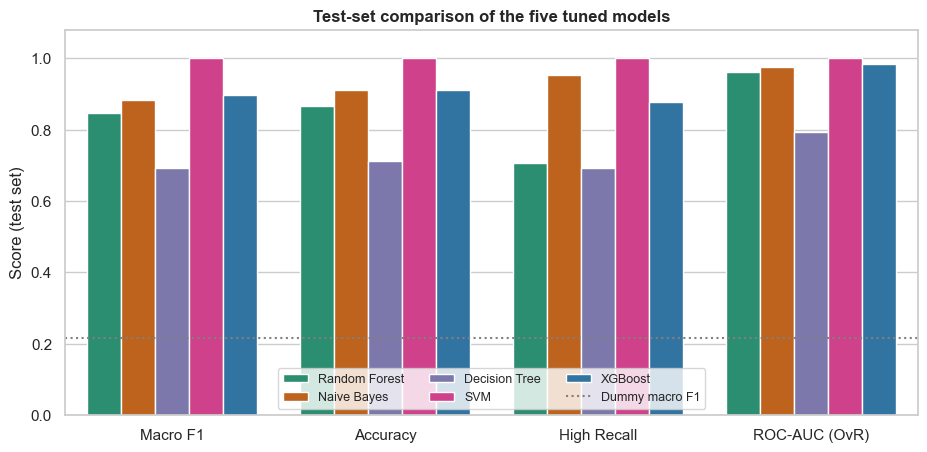

In [26]:
# Bar chart: key metrics across models
metrics_plot = ["Macro F1", "Accuracy", "High Recall", "ROC-AUC (OvR)"]
plot_df = comparison.drop(index="Dummy")[metrics_plot].reset_index().melt(id_vars="model", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, x="metric", y="score", hue="model", palette=MODEL_COLORS, ax=ax)
ax.set_ylim(0, 1.08); ax.set_xlabel(""); ax.set_ylabel("Score (test set)")
ax.axhline(comparison.loc["Dummy", "Macro F1"], color="grey", ls=":", label="Dummy macro F1")
ax.legend(ncol=3, loc="lower center", fontsize=9)
ax.set_title("Test-set comparison of the five tuned models")
save_fig("08_test_metrics_comparison")

**Observations**

* Test-set Macro F1: **SVM 1.000**, **XGBoost 0.897**, **Naive Bayes 0.883**, **Random Forest 0.846**, **Decision Tree 0.693** (Dummy 0.215). The test ranking matches the CV ranking, and test scores are consistent with the CV estimates (within about 0.04), which indicates the tuning did not overfit the CV folds.
* **High-stress recall:** SVM 1.000, Naive Bayes 0.954, XGBoost 0.877, Random Forest 0.708, Decision Tree 0.692. Naive Bayes achieves its high recall at a cost in **High precision (0.667)**: about one in three students it flags as High is not truly High. XGBoost balances the two better (precision 0.826, recall 0.877).
* **ROC-AUC (OvR macro):** XGBoost 0.985, Naive Bayes 0.977, Random Forest 0.963, Decision Tree 0.793 - the Decision Tree ranks students poorly; the SVM is perfect at 1.000.
* Note that Naive Bayes and XGBoost tie on accuracy (0.912) yet differ on Macro F1, a reminder of why accuracy alone is not enough.

## 8.2 Classification reports and confusion matrices

In [27]:
# Per-class classification report for each model
for name in MODEL_NAMES:
    pred = final_models[name].predict(X_test)
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=CLASS_ORDER, digits=3))

===== Random Forest =====
              precision    recall  f1-score   support

         Low      0.876     0.908     0.892       249
      Medium      0.855     0.867     0.861       286
        High      0.885     0.708     0.786        65

    accuracy                          0.867       600
   macro avg      0.872     0.827     0.846       600
weighted avg      0.867     0.867     0.866       600

===== Naive Bayes =====
              precision    recall  f1-score   support

         Low      0.967     0.956     0.962       249
      Medium      0.946     0.864     0.903       286
        High      0.667     0.954     0.785        65

    accuracy                          0.912       600
   macro avg      0.860     0.924     0.883       600
weighted avg      0.925     0.912     0.915       600

===== Decision Tree =====
              precision    recall  f1-score   support

         Low      0.760     0.751     0.756       249
      Medium      0.713     0.685     0.699       286

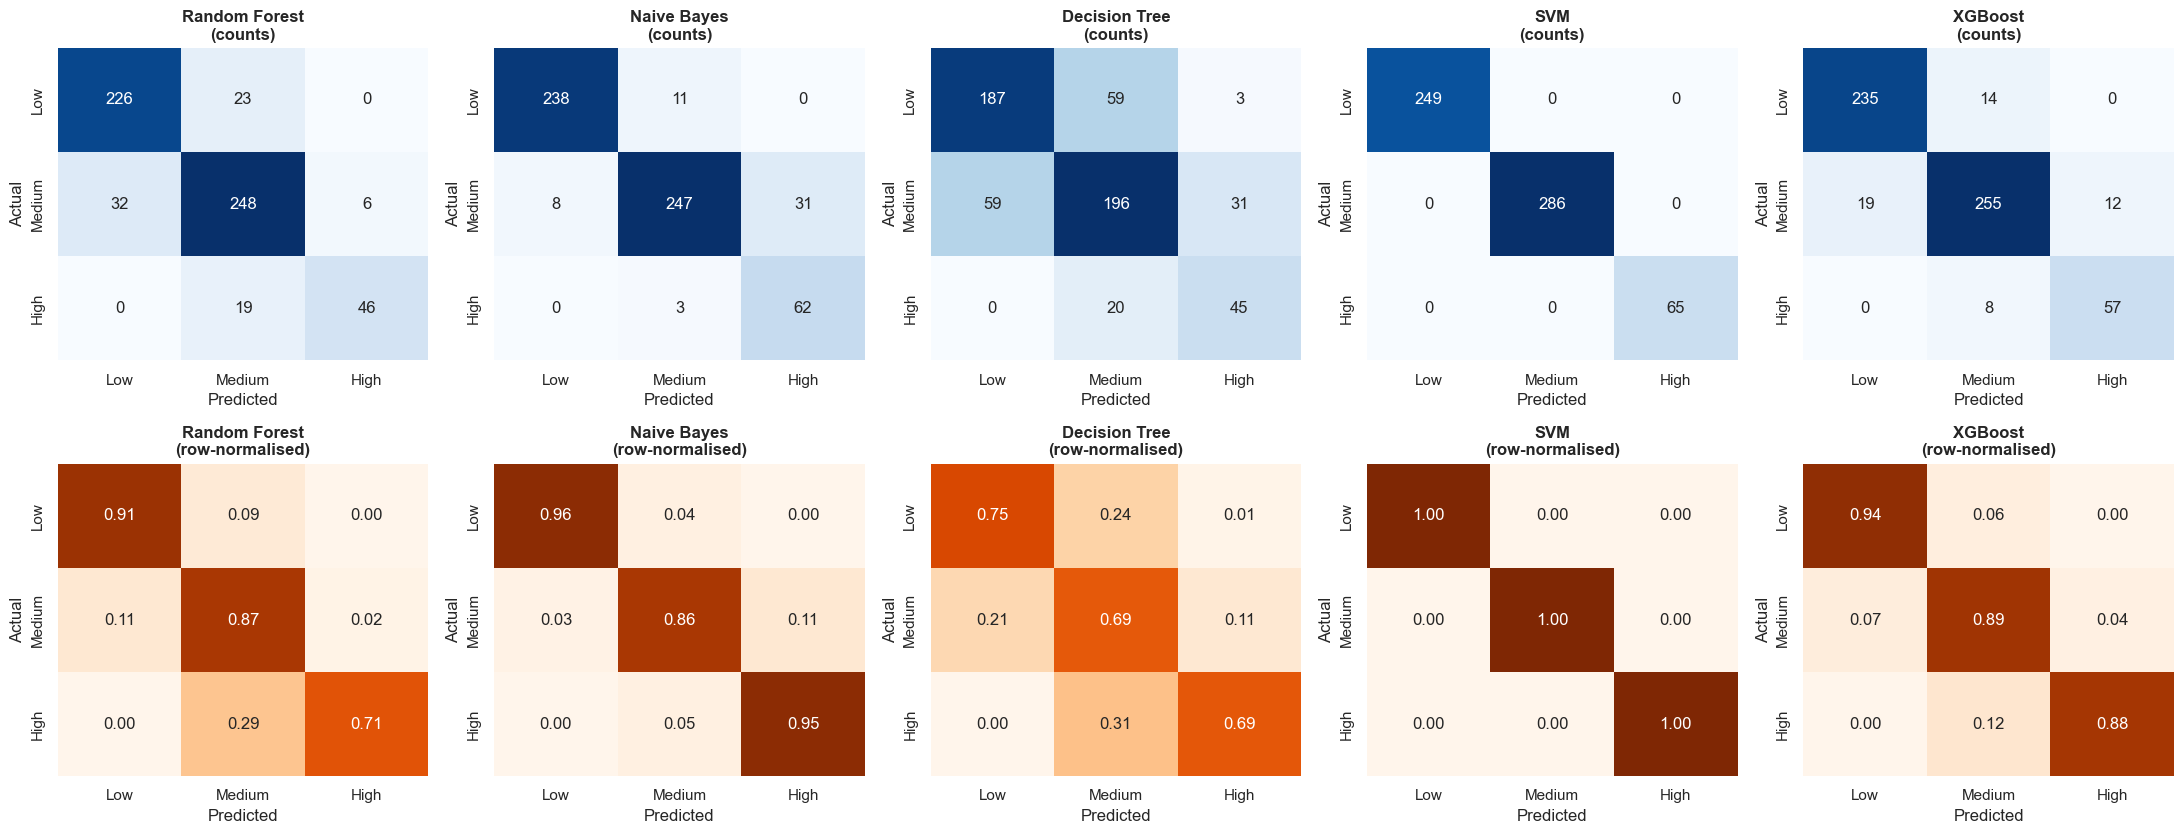

In [28]:
# Confusion matrices: raw counts (top) and row-normalised, i.e. per-class recall (bottom)
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
for j, name in enumerate(MODEL_NAMES):
    pred = final_models[name].predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[0, j])
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[1, j])
    axes[0, j].set_title(f"{name}\n(counts)"); axes[1, j].set_title(f"{name}\n(row-normalised)")
    for r in (0, 1):
        axes[r, j].set_xlabel("Predicted"); axes[r, j].set_ylabel("Actual")
plt.tight_layout()
save_fig("09_confusion_matrices")

## 8.3 High-stress miss analysis
The stakeholder's costliest error is a **truly High-stress student predicted as Low or Medium**. We count these misses per model.

,High in test,High caught,High->Low,High->Medium,High miss rate,False alarms (non-High predicted High)
model,,,,,,
Random Forest,65,46,0,19,29.2%,6
Naive Bayes,65,62,0,3,4.6%,31
Decision Tree,65,45,0,20,30.8%,34
SVM,65,65,0,0,0.0%,0
XGBoost,65,57,0,8,12.3%,12


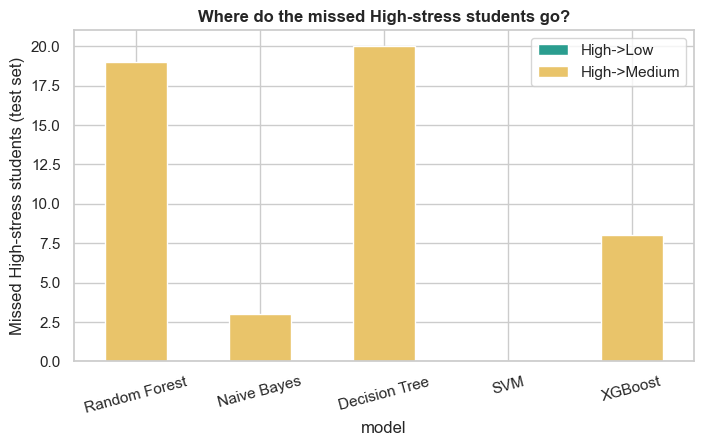

In [29]:
miss_rows = []
for name in MODEL_NAMES:
    pred = final_models[name].predict(X_test)
    is_high = (y_test.values == HIGH)
    n_high = int(is_high.sum())
    to_low = int(((pred == 0) & is_high).sum()); to_med = int(((pred == 1) & is_high).sum())
    miss_rows.append([name, n_high, n_high - to_low - to_med, to_low, to_med, (to_low + to_med) / n_high,
                      int(((pred == HIGH) & ~is_high).sum())])
miss = pd.DataFrame(miss_rows, columns=["model", "High in test", "High caught", "High->Low", "High->Medium",
                                        "High miss rate", "False alarms (non-High predicted High)"]).set_index("model")
display(miss.style.format({"High miss rate": "{:.1%}"}))

ax = miss[["High->Low", "High->Medium"]].plot(kind="bar", stacked=True, color=[CLASS_COLORS["Low"], CLASS_COLORS["Medium"]],
                                              figsize=(8, 4.3), rot=15)
ax.set_ylabel("Missed High-stress students (test set)"); ax.set_title("Where do the missed High-stress students go?")
save_fig("10_high_stress_misses")

**Observations**

Out of the 65 High-stress students in the test set, the number **missed** is: SVM 0, Naive Bayes 3, XGBoost 8, Random Forest 19, Decision Tree 20 (miss rates 0%, 4.6%, 12.3%, 29.2%, 30.8%). Random Forest and the Decision Tree therefore overlook roughly three in ten High-stress students, which is unacceptable for a screening tool whose purpose is to catch them. **Every single miss is a High to Medium error and there are no High to Low errors** in any model: the models never confuse the extremes, only the neighbouring classes, which is the milder kind of error (those students are still flagged as at-risk to some degree). The price of high recall is false alarms: Naive Bayes raises 31 false High alarms (precision 0.667), the Decision Tree 34, XGBoost 12, Random Forest 6 and the SVM none.

## 8.4 ROC and Precision-Recall curves for the High class (one-vs-rest)

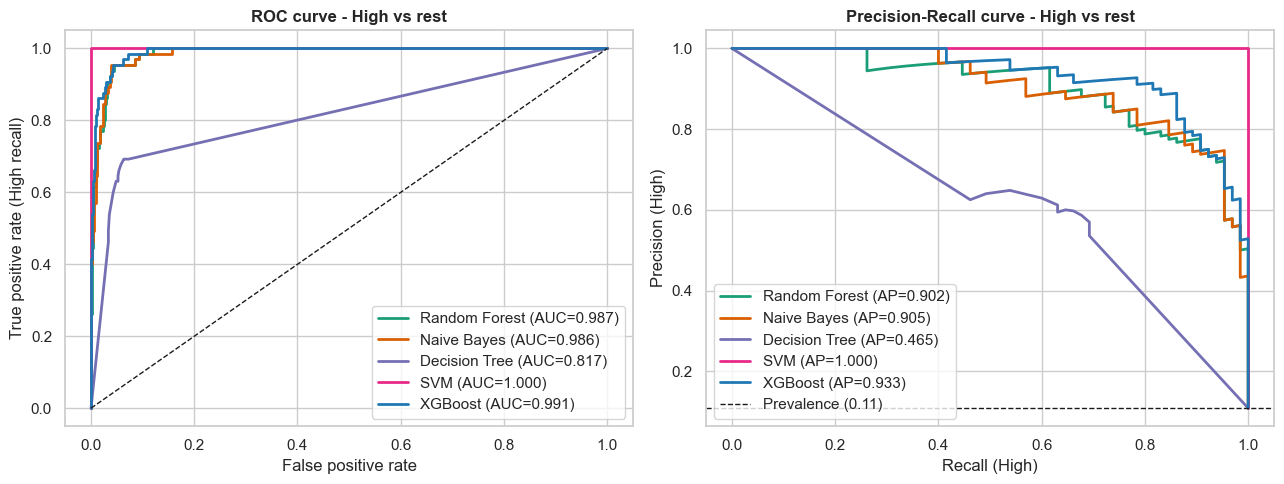

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
y_high = (y_test.values == HIGH).astype(int)
for name in MODEL_NAMES:
    p_high = get_proba(final_models[name], X_test)[:, HIGH]
    fpr, tpr, _ = roc_curve(y_high, p_high)
    prec, rec, _ = precision_recall_curve(y_high, p_high)
    ax[0].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f"{name} (AUC={roc_auc_score(y_high, p_high):.3f})")
    ax[1].plot(rec, prec, color=MODEL_COLORS[name], lw=2, label=f"{name} (AP={average_precision_score(y_high, p_high):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (High recall)")
ax[0].set_title("ROC curve - High vs rest"); ax[0].legend(loc="lower right")
ax[1].axhline(y_high.mean(), color="k", ls="--", lw=1, label=f"Prevalence ({y_high.mean():.2f})")
ax[1].set_xlabel("Recall (High)"); ax[1].set_ylabel("Precision (High)"); ax[1].set_title("Precision-Recall curve - High vs rest")
ax[1].legend(loc="lower left")
plt.tight_layout()
save_fig("11_roc_pr_curves_high_class")

**Observations**

The curves rank the models consistently with the metrics table: the SVM curve hugs the top-left corner (perfect separation), XGBoost and Naive Bayes are very close to it, Random Forest is slightly lower, and the Decision Tree is clearly below the others. In the Precision-Recall plot (more informative under imbalance because it ignores true negatives) the differences between models are larger than in the ROC plot, and the dashed line shows the precision of a random guesser, i.e. the High prevalence of about 0.11. A counselling unit that prefers more recall can lower the decision threshold along these curves at the price of extra false alarms.

## 8.5 Overfitting check: train vs test Macro F1

,train F1,CV F1 (train folds),test F1,train-test gap
model,,,,
Random Forest,0.9905,0.8258,0.8463,0.1441
Naive Bayes,0.8538,0.8469,0.8832,-0.0294
Decision Tree,0.9391,0.7135,0.6931,0.2460
SVM,1.0000,1.0000,1.0000,0.0000
XGBoost,0.9929,0.8925,0.8970,0.0959


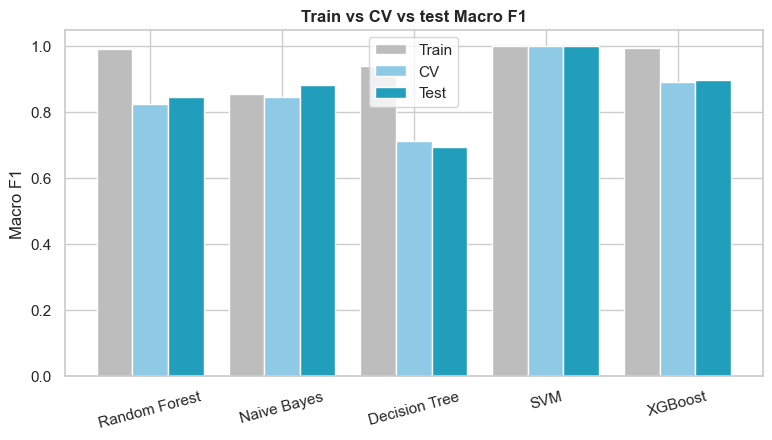

In [31]:
# A big gap between train and test performance signals overfitting
gap_rows = []
for name in MODEL_NAMES:
    tr = f1_score(y_train, final_models[name].predict(X_train), average="macro")
    te = f1_score(y_test, final_models[name].predict(X_test), average="macro")
    gap_rows.append([name, tr, tuned_cv.loc[name, "f1_macro_mean"], te, tr - te])
gap = pd.DataFrame(gap_rows, columns=["model", "train F1", "CV F1 (train folds)", "test F1", "train-test gap"]).set_index("model")
display(gap.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(gap)); w = 0.27
ax.bar(x - w, gap["train F1"], w, label="Train", color="#bdbdbd")
ax.bar(x, gap["CV F1 (train folds)"], w, label="CV", color="#8ecae6")
ax.bar(x + w, gap["test F1"], w, label="Test", color="#219ebc")
ax.set_xticks(x); ax.set_xticklabels(gap.index, rotation=15); ax.set_ylim(0, 1.05); ax.set_ylabel("Macro F1")
ax.legend(); ax.set_title("Train vs CV vs test Macro F1")
save_fig("12_overfitting_check")

**Observations**

* **Decision Tree** has the largest train-test gap (0.246) and **Random Forest** a large one (0.144), i.e. they memorise training data (training F1 0.94 and 0.99 against 0.69 and 0.85 on test). **XGBoost** overfits moderately (gap 0.096).
* **Naive Bayes** (gap -0.029, test slightly higher than train) and the **linear SVM** (gap 0.000) generalise stably - they are low-variance, high-bias models whose assumptions happen to fit this data well.
* For all models the CV estimate is a good predictor of test performance, so the reported test scores are trustworthy for *this* dataset.

## 8.6 Selecting the best model
We choose with a documented rule that does **not** rely on the test set for selection (to avoid optimistic bias): the model with the highest **cross-validated Macro F1**; the test set then serves as an independent confirmation. High-stress recall, CV stability (std) and interpretability are used as secondary criteria and discussed below.

In [32]:
# Primary: highest CV Macro F1 (selection on training folds only). Test set = confirmation.
best_name = tuned_cv["f1_macro_mean"].idxmax()
best_model = final_models[best_name]
print(f"Best model by CV Macro F1: {best_name}  (CV {tuned_cv.loc[best_name, 'f1_macro_mean']:.4f} "
      f"+/- {tuned_cv.loc[best_name, 'f1_macro_std']:.4f})")

ranking = pd.DataFrame({
    "CV F1 mean": tuned_cv["f1_macro_mean"], "CV F1 std": tuned_cv["f1_macro_std"],
    "Test Macro F1": real["Macro F1"], "Test High Recall": real["High Recall"],
    "High->Low/Med misses": miss["High->Low"] + miss["High->Medium"],
}).sort_values("CV F1 mean", ascending=False)
ranking["Rank (CV F1)"] = range(1, len(ranking) + 1)
display(ranking.round(4))

# Is the best model's lead over the runner-up larger than fold noise? (paired per-fold comparison on identical folds)
top2 = ranking.index[:2].tolist()
f1_folds = {n: [grid_searches[n].cv_results_[f"split{i}_test_f1_macro"][grid_searches[n].best_index_] for i in range(5)] for n in top2}
d = np.array(f1_folds[top2[0]]) - np.array(f1_folds[top2[1]])
print(f"{top2[0]} minus {top2[1]}: mean per-fold F1 difference = {d.mean():+.4f} (std {d.std(ddof=1):.4f}, "
      f"{(d > 0).sum()}/5 folds won)")

Best model by CV Macro F1: SVM  (CV 1.0000 +/- 0.0000)


,CV F1 mean,CV F1 std,Test Macro F1,Test High Recall,High->Low/Med misses,Rank (CV F1)
model,,,,,,
SVM,1.0000,0.0000,1.0000,1.0000,0,1
XGBoost,0.8925,0.0178,0.8970,0.8769,8,2
Naive Bayes,0.8469,0.0207,0.8832,0.9538,3,3
Random Forest,0.8258,0.0243,0.8463,0.7077,19,4
Decision Tree,0.7135,0.0144,0.6931,0.6923,20,5


SVM minus XGBoost: mean per-fold F1 difference = +0.1075 (std 0.0199, 5/5 folds won)


### 8.6.1 Investigation: why is the SVM perfect? (leakage audit)
A test Macro F1 of 1.000 is suspicious and must be investigated before it is believed. Two possible causes: (a) **a leaking column is among the features** - we verify that `Stress_Score`/`Timestamp` are not in `FEATURES`; (b) the label is a **deterministic function of the legitimate features**, which a linear SVM could discover. To test (b) we fit an ordinary linear regression that predicts `Stress_Score` from the 15 predictors. `Stress_Score` is used here **only as a diagnostic target**, never as a model input.

In [33]:
# (a) No leaking columns among the model inputs
print("Stress_Score in FEATURES?", "Stress_Score" in FEATURES, "| Timestamp in FEATURES?", "Timestamp" in FEATURES)
print("Train/test row overlap (index):", len(set(X_train.index) & set(X_test.index)))

# (b) Can a plain linear regression reproduce Stress_Score from the 15 legitimate predictors?
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
Xd = pd.get_dummies(df_full[FEATURES], drop_first=True).astype(float)
# (macOS BLAS emits spurious RuntimeWarnings inside matmul for this well-conditioned problem; results are verified below)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    lin = LinearRegression().fit(Xd.loc[X_train.index], df_full.loc[X_train.index, "Stress_Score"])
    score_test_pred = lin.predict(Xd.loc[X_test.index])
score_test_true = df_full.loc[X_test.index, "Stress_Score"]
print(f"Linear regression (fit on TRAIN) -> test R^2 = {r2_score(score_test_true, score_test_pred):.6f}, "
      f"max abs error = {np.abs(score_test_pred - score_test_true).max():.2e} score points")

coefs = pd.Series(lin.coef_, index=Xd.columns).round(3)
display(coefs[coefs.abs() > 1e-6].sort_values(ascending=False).to_frame("coefficient"))
print("Features with ZERO coefficient (no effect on the score):", list(coefs[coefs.abs() <= 1e-6].index))
print(f"Intercept = {lin.intercept_:.3f}")

# Applying the published thresholds to the regression's predicted score reproduces the labels
rule_pred = pd.cut(pd.Series(score_test_pred).round(), bins=[-np.inf, 10, 20, np.inf], labels=[0, 1, 2]).astype(int)
print(f"Thresholds on the linear score reproduce test labels for {(rule_pred.values == y_test.values).mean():.2%} of students")

Stress_Score in FEATURES? False | Timestamp in FEATURES? False
Train/test row overlap (index): 0
Linear regression (fit on TRAIN) -> test R^2 = 1.000000, max abs error = 7.46e-14 score points


,coefficient
Exam_Frequency,1.0
Assignment_Load,1.0
Social_Media_Use,1.0
Screen_Time,1.0
Anxiety_Level,1.0
Sleep_Hours,-1.0
Family_Support,-1.0
Physical_Exercise_Yes,-2.0


Features with ZERO coefficient (no effect on the score): ['Age', 'Study_Hours', 'Class_Attendance', 'Peer_Pressure', 'Gender_Male', 'Tuition_Yes', 'Family_Income_Level_Low', 'Family_Income_Level_Medium', 'University_Type_Private University', 'University_Type_Public University']
Intercept = 0.000
Thresholds on the linear score reproduce test labels for 100.00% of students


**Conclusion of the audit.** There is no leaking column in the model inputs, but the audit reveals something equally important: `Stress_Score` is an *exact linear function* of eight of the predictors (R-squared of 1.0 and errors at machine precision), and `Stress_Level` is a threshold on it. The label is therefore a deterministic, linear rule over the legitimate features: a linear-kernel SVM can recover that rule exactly, hence its perfect score. This is not leakage from the future or from the answer column, but it **does mean the dataset is synthetically generated by a formula**, and the perfect accuracy must not be expected on real students. We keep the SVM result (it is a correct finding about this dataset) but interpret it cautiously in the conclusions.

**Observations**

**Selected model: SVM (linear kernel, C = 10).**

| Criterion | Evidence |
|---|---|
| Macro F1 (primary) | CV 1.000 +/- 0.000; test 1.000 - highest by a wide margin |
| High-stress recall (secondary) | 1.000 on test, 0 of 65 High students missed (runner-up XGBoost missed 8) |
| CV stability | std 0.000 across folds; it also beats XGBoost in 5 of 5 folds with a mean per-fold gap of +0.108 (std 0.020), far larger than the fold noise |
| Overfitting | train-test gap 0.000 |
| Interpretability | a linear SVM is a weighted sum of features - far easier to explain than a boosted forest (the weights can be shown to counsellors) |

**If the stakeholder prefers a probabilistic, easily-explained alternative**, Naive Bayes is the best runner-up on High recall (0.954) but has lower precision (0.667); **XGBoost** is the most balanced non-linear alternative (Macro F1 0.897, High recall 0.877, ROC-AUC 0.985). The result should be read together with the audit above: the SVM wins because the labels in this dataset follow an exact linear rule, so its perfect score is a property of the data and an upper bound for real-world use.

## 8.7 Feature importance
Three complementary views: (1) **built-in importance** of Random Forest (mean decrease in impurity) and XGBoost (gain), computed on the encoded features; (2) **permutation importance** of the best model on the *test set* with Macro F1 as the score - model-agnostic and measured on original (un-encoded) columns; (3) a roll-up to **feature groups**.

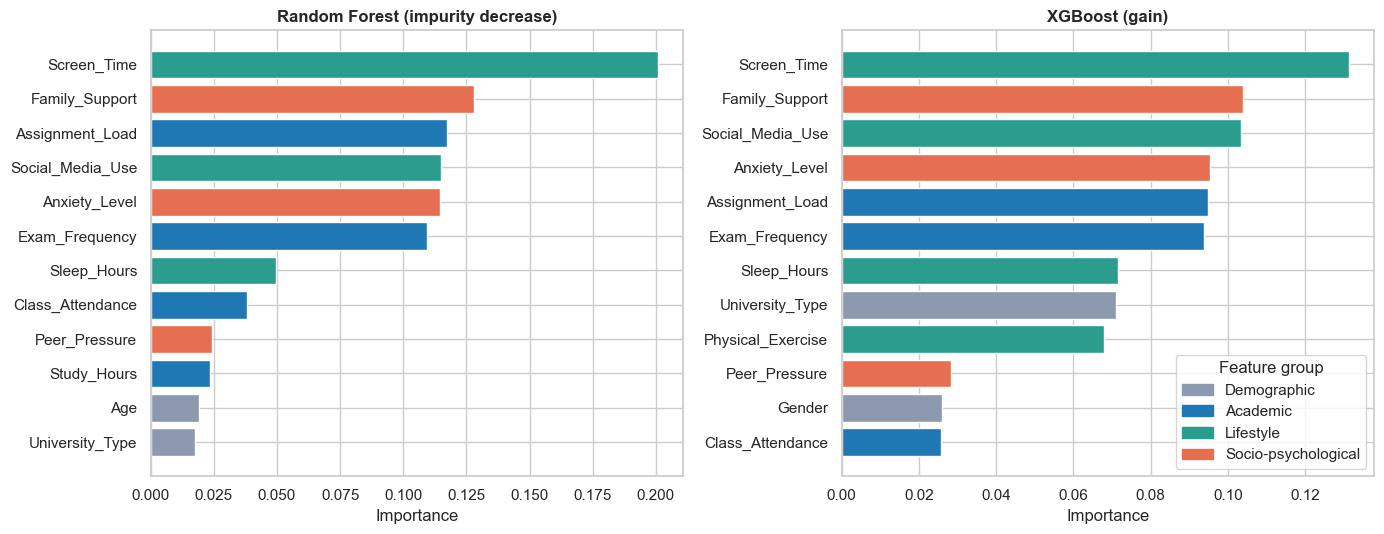

Top 5 RF : ['Screen_Time', 'Family_Support', 'Assignment_Load', 'Social_Media_Use', 'Anxiety_Level']
Top 5 XGB: ['Screen_Time', 'Family_Support', 'Social_Media_Use', 'Anxiety_Level', 'Assignment_Load']


In [34]:
# Built-in importance of RF and XGB (encoded feature names; one-hot University_Type is aggregated back)
enc_names = [n.split("__", 1)[1] for n in final_models["Random Forest"].named_steps["prep"].get_feature_names_out()]

def aggregate_onehot(names, values):
    """Sum the importance of one-hot columns (University_Type_*) back into one original feature."""
    s = pd.Series(values, index=names)
    uni = [n for n in s.index if n.startswith("University_Type_")]
    s["University_Type"] = s[uni].sum(); s = s.drop(uni)
    return s.sort_values(ascending=False)

imp_rf  = aggregate_onehot(enc_names, final_models["Random Forest"].named_steps["clf"].feature_importances_)
imp_xgb = aggregate_onehot(enc_names, final_models["XGBoost"].named_steps["clf"].feature_importances_)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, imp, title, c in [(ax[0], imp_rf, "Random Forest (impurity decrease)", MODEL_COLORS["Random Forest"]),
                         (ax[1], imp_xgb, "XGBoost (gain)", MODEL_COLORS["XGBoost"])]:
    top = imp.head(12)[::-1]
    a.barh(top.index, top.values, color=[GROUP_COLORS[FEATURE_GROUP[f]] for f in top.index])
    a.set_title(title); a.set_xlabel("Importance")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax[1].legend(handles, GROUP_COLORS.keys(), title="Feature group", loc="lower right")
plt.tight_layout()
save_fig("13_builtin_feature_importance")
print("Top 5 RF :", list(imp_rf.index[:5]))
print("Top 5 XGB:", list(imp_xgb.index[:5]))

,importance_mean,importance_std,group
Screen_Time,0.3625,0.0210,Lifestyle
Assignment_Load,0.2986,0.0155,Academic
Exam_Frequency,0.2839,0.0174,Academic
Family_Support,0.2784,0.0156,Socio-psychological
Anxiety_Level,0.2601,0.0143,Socio-psychological
Social_Media_Use,0.2546,0.0147,Lifestyle
Sleep_Hours,0.1729,0.0134,Lifestyle
Physical_Exercise,0.1010,0.0127,Lifestyle
Age,0.0000,0.0000,Demographic
Study_Hours,0.0000,0.0000,Academic


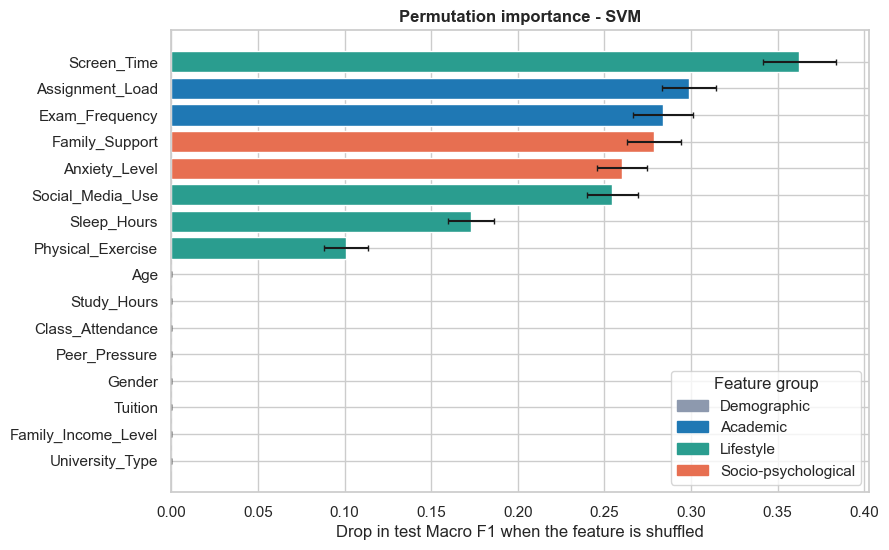


Share of permutation importance by feature group (%):


,share %
group,
Lifestyle,44.3
Academic,29.0
Socio-psychological,26.8
Demographic,0.0


In [35]:
# Permutation importance of the BEST model on the test set (scoring = macro F1), 30 repeats
perm = permutation_importance(best_model, X_test, y_test, scoring="f1_macro", n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({"importance_mean": perm.importances_mean, "importance_std": perm.importances_std}, index=X_test.columns)
             .sort_values("importance_mean", ascending=False))
perm_df["group"] = [FEATURE_GROUP[f] for f in perm_df.index]
display(perm_df.round(4))

fig, ax = plt.subplots(figsize=(9, 6))
top = perm_df.iloc[::-1]
ax.barh(top.index, top["importance_mean"], xerr=top["importance_std"], capsize=2,
        color=[GROUP_COLORS[g] for g in top["group"]])
ax.set_xlabel("Drop in test Macro F1 when the feature is shuffled")
ax.set_title(f"Permutation importance - {best_name}")
ax.legend(handles, GROUP_COLORS.keys(), title="Feature group", loc="lower right")
save_fig("14_permutation_importance_best_model")

# Roll-up to feature groups (share of total positive permutation importance)
grp = perm_df.assign(imp=perm_df["importance_mean"].clip(lower=0)).groupby("group")["imp"].sum()
grp = (grp / grp.sum() * 100).sort_values(ascending=False)
print("\nShare of permutation importance by feature group (%):"); display(grp.round(1).to_frame("share %"))
top5_features = list(perm_df.index[:5])

**Observations**

* **Built-in importance** (RF and XGBoost) agree on the top five factors: Screen_Time, Family_Support, Assignment_Load, Social_Media_Use and Anxiety_Level (in slightly different order).
* **Permutation importance of the best model** (drop in test Macro F1 when a feature is shuffled): Screen_Time 0.36, Assignment_Load 0.30, Exam_Frequency 0.28, Family_Support 0.28, Anxiety_Level 0.26, Social_Media_Use 0.25, Sleep_Hours 0.17, Physical_Exercise 0.10. **Eight features have exactly zero importance**: Age, Study_Hours, Class_Attendance, Peer_Pressure, Gender, Tuition, Family_Income_Level and University_Type. This matches the statistical tests of Section 5.5 exactly.
* **By feature group**, Lifestyle factors (screen time, social media, sleep, exercise) account for about 44% of the importance, Academic (assignments, exams) 29%, Socio-psychological (family support, anxiety) 27%, and **Demographic 0%**. In other words stress in this dataset is driven by modifiable behaviour and circumstances, not by who the student is.
* Why is Screen_Time first? It is not because each hour weighs more than the other factors (the audit shows equal weights for the six numeric drivers) but because it has the **widest range of values** (1-11 hours, standard deviation 3.2 against about 2.6 for the 1-9 scales), so it moves the total score more. Importance reflects effect times variability.

## 8.8 Decision Tree interpretation
The tuned Decision Tree can be deep. For stakeholder communication we additionally train a **shallow, readable tree (max depth 3)** on the *unscaled* encoded features (so thresholds are in original units: hours, scale points) and report how much accuracy this simplification costs.

Depth-3 tree  -> test Macro F1 0.5870 | accuracy 0.6317 | High recall 0.5077


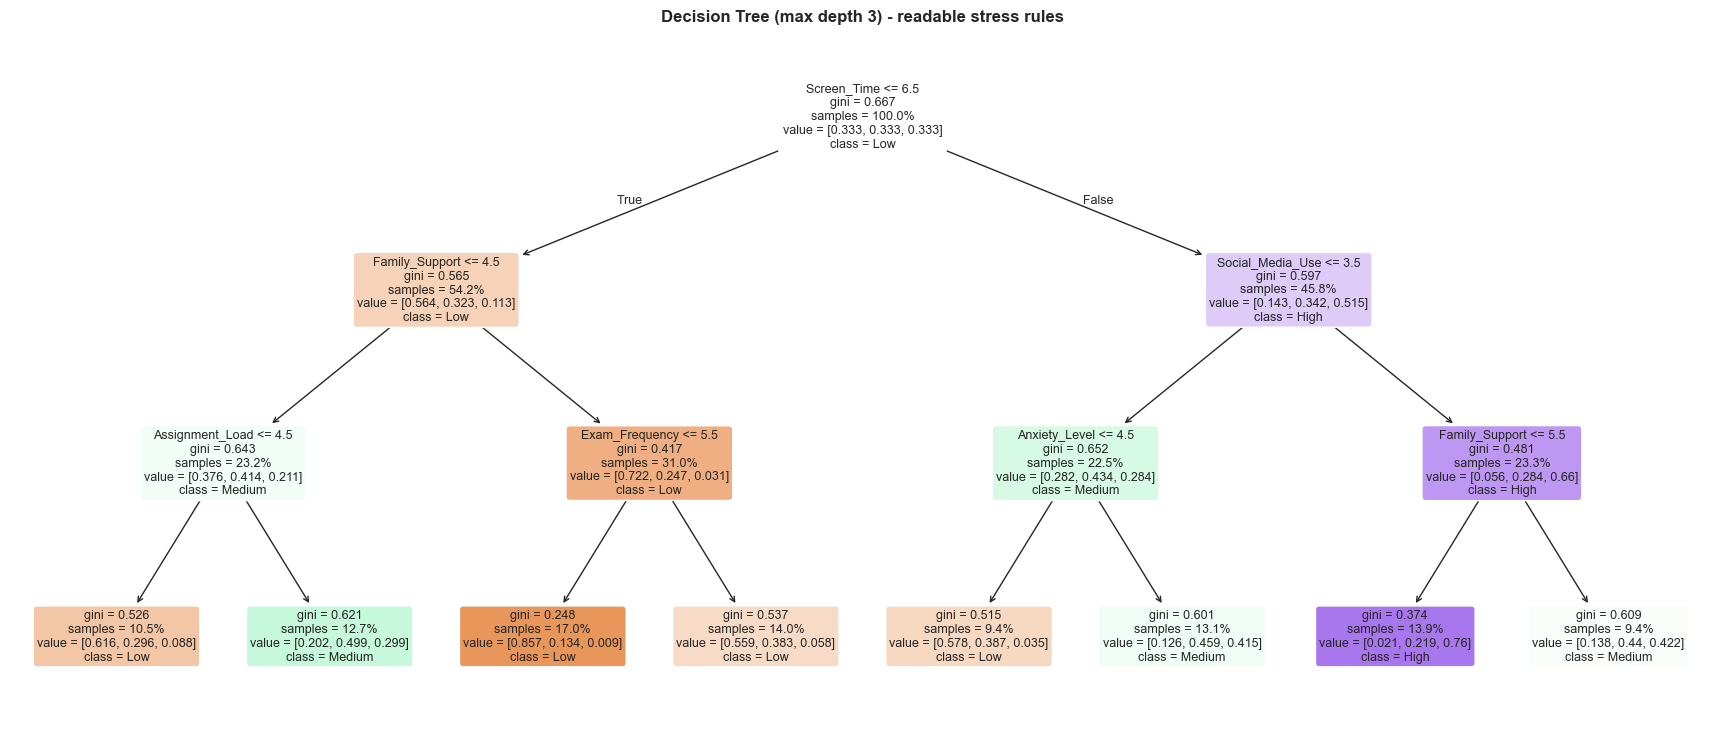

|--- Screen_Time <= 6.50
|   |--- Family_Support <= 4.50
|   |   |--- Assignment_Load <= 4.50
|   |   |   |--- class: 0
|   |   |--- Assignment_Load >  4.50
|   |   |   |--- class: 1
|   |--- Family_Support >  4.50
|   |   |--- Exam_Frequency <= 5.50
|   |   |   |--- class: 0
|   |   |--- Exam_Frequency >  5.50
|   |   |   |--- class: 0
|--- Screen_Time >  6.50
|   |--- Social_Media_Use <= 3.50
|   |   |--- Anxiety_Level <= 4.50
|   |   |   |--- class: 0
|   |   |--- Anxiety_Level >  4.50
|   |   |   |--- class: 1
|   |--- Social_Media_Use >  3.50
|   |   |--- Family_Support <= 5.50
|   |   |   |--- class: 2
|   |   |--- Family_Support >  5.50
|   |   |   |--- class: 1



In [36]:
# Shallow, human-readable tree on unscaled features (thresholds stay in original units)
tree_pipe = make_pipe(DecisionTreeClassifier(max_depth=3, class_weight="balanced", min_samples_leaf=20,
                                             random_state=RANDOM_STATE), scale=False).fit(X_train, y_train)
tree_feat = [n.split("__", 1)[1] for n in tree_pipe.named_steps["prep"].get_feature_names_out()]
tree_pred = tree_pipe.predict(X_test)
print(f"Depth-3 tree  -> test Macro F1 {f1_score(y_test, tree_pred, average='macro'):.4f} | "
      f"accuracy {accuracy_score(y_test, tree_pred):.4f} | High recall {recall_score(y_test, tree_pred, labels=[HIGH], average='macro'):.4f}")

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree_pipe.named_steps["clf"], feature_names=tree_feat, class_names=CLASS_ORDER, filled=True,
          rounded=True, proportion=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree (max depth 3) - readable stress rules")
save_fig("15_decision_tree_depth3")

print(export_text(tree_pipe.named_steps["clf"], feature_names=tree_feat, show_weights=False))

**Observations**

The shallow depth-3 tree is easy to read but **much less accurate** (test Macro F1 0.587, accuracy 0.632, High recall 0.508) than the tuned models; this is the price of interpretability. Reading the rules in plain language:

* If **screen time is at most 6 hours** and family support is low (4 or less) with a heavy assignment load (above 4), the tree predicts *Medium*; otherwise it predicts *Low*.
* If **screen time is above 6 hours**, high social-media use (above 3 hours) *and* low family support (5 or less), the tree predicts **High** - the only leaf that predicts High.
* High screen time with lower social-media use, high anxiety (above 4) leads to Medium, lower anxiety to Low.

So the tree rediscovers the main drivers (screen time, social media, family support, assignment load, anxiety) and a clear "red-flag profile" for counsellors: *long screen time + heavy social media + weak family support*. Why is it so much weaker than the SVM? The stress score is a **sum of seven factors**, and a tree can only make axis-parallel cuts, so it needs a very deep tree to approximate a diagonal (linear) boundary; this is also why the tuned Decision Tree (depth 10) remains the weakest model (test Macro F1 0.693) and overfits.

## 8.9 Demo: predicting stress for hypothetical student profiles

In [37]:
# Three illustrative (invented) profiles scored by the best model
profiles = pd.DataFrame([
    # a well-balanced student
    dict(Age=21, Gender="Female", Study_Hours=4, Class_Attendance=85, Tuition="No", Exam_Frequency=3, Assignment_Load=3,
         Sleep_Hours=8, Physical_Exercise="Yes", Social_Media_Use=2, Screen_Time=4, Family_Income_Level="Medium",
         Peer_Pressure=3, Family_Support=8, Anxiety_Level=2, University_Type="Public University"),
    # a student with moderate load
    dict(Age=22, Gender="Male", Study_Hours=5, Class_Attendance=70, Tuition="Yes", Exam_Frequency=5, Assignment_Load=5,
         Sleep_Hours=6, Physical_Exercise="No", Social_Media_Use=4, Screen_Time=6, Family_Income_Level="Medium",
         Peer_Pressure=5, Family_Support=5, Anxiety_Level=5, University_Type="Private University"),
    # a student with heavy load, little sleep, long screen time, low support
    dict(Age=23, Gender="Male", Study_Hours=8, Class_Attendance=55, Tuition="Yes", Exam_Frequency=8, Assignment_Load=9,
         Sleep_Hours=4, Physical_Exercise="No", Social_Media_Use=6, Screen_Time=10, Family_Income_Level="Low",
         Peer_Pressure=8, Family_Support=2, Anxiety_Level=8, University_Type="National University"),
], index=["A: balanced", "B: moderate", "C: overloaded"])[FEATURES]
proba = best_model.predict_proba(profiles)
demo = pd.DataFrame(proba, columns=[f"P({c})" for c in CLASS_ORDER], index=profiles.index)
demo["Predicted"] = [CLASS_ORDER[i] for i in proba.argmax(axis=1)]
display(demo.style.format({f"P({c})": "{:.2f}" for c in CLASS_ORDER}))

,P(Low),P(Medium),P(High),Predicted
A: balanced,1.00,0.00,0.00,Low
B: moderate,0.00,1.00,0.00,Medium
C: overloaded,0.00,0.00,1.00,High


**Reading the demo**

The three invented profiles are classified as Low (balanced, low-load student), Medium (average) and High (long screen time, heavy workload, little sleep, low family support, high anxiety) with probabilities close to 1.00. The probabilities are this extreme because the linear SVM separates this data perfectly (its Platt-scaled probabilities saturate); real-world probabilities would be less confident.

**8.10 Stakeholder insights and recommendations**

**What drives high stress (in this dataset)**
1. **Digital load:** long screen time and heavy social-media use are the strongest drivers; High-stress students average about 8.7 screen hours a day versus 4.4 for Low-stress students.
2. **Academic load:** many exams per semester and a heavy assignment load are strongly associated with stress.
3. **Anxiety** is higher in stressed students, while **family support** and **sleep** are protective; **physical exercise** is associated with lower stress.
4. **Demographics do not matter:** age, gender, university type, family income, tuition and even attendance, study hours and peer pressure show no relationship, so stress cannot be inferred from who a student is.

**Recommendations for the counselling / student-affairs unit**
* **Screen with the model, then talk:** use the model as a short-questionnaire triage tool and prioritise students predicted High (a threshold that favours High recall; a false alarm costs only a short conversation, a miss costs a student's well-being).
* **Digital-wellbeing programmes:** workshops on screen-time and social-media management, since these are the largest and most modifiable drivers.
* **Academic workload coordination:** work with faculties to spread exams and assignment deadlines (avoid clusters of exams and large deliveries in the same weeks).
* **Sleep and exercise promotion:** sleep-hygiene campaigns and accessible sport/exercise activities, both associated with lower stress.
* **Strengthen support networks:** outreach to students reporting low family support (peer-mentoring, buddy systems, family-involvement events) and early anxiety counselling.
* **Do not target by demographics:** resources aimed by gender, income or university type would not be supported by this data.
* **Caution:** the data suggest association, not causation, and the unusually clean structure indicates synthetic data (Section 9.3); pilot the approach on real campus data before any operational use.

# 9. Conclusion and Suggestions

## 9.1 Key findings (generated from the results above, so the numbers are exact)

In [38]:
# Final summary generated from live variables so every number is accurate
b = best_name
lines = [
 f"* Dataset: {len(df_full)} students, {len(FEATURES)} predictors after dropping Stress_Score (leakage: label is a pure threshold rule on it) and Timestamp.",
 f"* Class balance: Low {target_counts['Low']} ({target_pct['Low']}%), Medium {target_counts['Medium']} ({target_pct['Medium']}%), High {target_counts['High']} ({target_pct['High']}%).",
 f"* Dummy (always Medium) test Macro F1 = {comparison.loc['Dummy', 'Macro F1']:.3f}; all five models are far above this reference.",
 f"* Best model by CV Macro F1: {b} (CV {tuned_cv.loc[b, 'f1_macro_mean']:.3f} +/- {tuned_cv.loc[b, 'f1_macro_std']:.3f}); "
 f"test Macro F1 = {comparison.loc[b, 'Macro F1']:.3f}, accuracy = {comparison.loc[b, 'Accuracy']:.3f}, "
 f"High recall = {comparison.loc[b, 'High Recall']:.3f}, High precision = {comparison.loc[b, 'High Precision']:.3f}, ROC-AUC = {comparison.loc[b, 'ROC-AUC (OvR)']:.3f}.",
 f"* Highest test Macro F1 overall: {real['Macro F1'].idxmax()} ({real['Macro F1'].max():.3f}); highest High recall: {real['High Recall'].idxmax()} ({real['High Recall'].max():.3f}).",
 f"* Missed High-stress students ({b}): {int(miss.loc[b, 'High->Low'])} to Low and {int(miss.loc[b, 'High->Medium'])} to Medium out of {int(miss.loc[b, 'High in test'])} High cases in the test set.",
 f"* Top 5 features by permutation importance ({b}): " + ", ".join(top5_features) + ".",
 f"* Train-test Macro F1 gap of {b}: {gap.loc[b, 'train-test gap']:+.3f}.",
]
display(Markdown("\n".join(lines)))
display(comparison.round(3))

* Dataset: 3000 students, 16 predictors after dropping Stress_Score (leakage: label is a pure threshold rule on it) and Timestamp.
* Class balance: Low 1243 (41.43%), Medium 1431 (47.7%), High 326 (10.87%).
* Dummy (always Medium) test Macro F1 = 0.215; all five models are far above this reference.
* Best model by CV Macro F1: SVM (CV 1.000 +/- 0.000); test Macro F1 = 1.000, accuracy = 1.000, High recall = 1.000, High precision = 1.000, ROC-AUC = 1.000.
* Highest test Macro F1 overall: SVM (1.000); highest High recall: SVM (1.000).
* Missed High-stress students (SVM): 0 to Low and 0 to Medium out of 65 High cases in the test set.
* Top 5 features by permutation importance (SVM): Screen_Time, Assignment_Load, Exam_Frequency, Family_Support, Anxiety_Level.
* Train-test Macro F1 gap of SVM: +0.000.

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,High Recall,High Precision,ROC-AUC (OvR)
model,,,,,,,,
Dummy,0.477,0.159,0.333,0.215,0.308,0.000,0.000,0.500
Random Forest,0.867,0.872,0.827,0.846,0.866,0.708,0.885,0.963
Naive Bayes,0.912,0.860,0.924,0.883,0.915,0.954,0.667,0.977
Decision Tree,0.713,0.681,0.710,0.693,0.714,0.692,0.570,0.793
SVM,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
XGBoost,0.912,0.891,0.904,0.897,0.912,0.877,0.826,0.985


**9.2 Discussion**

* **Which model?** The SVM (linear kernel) is selected: it is best on Macro F1 and on High recall, stable across folds, and does not overfit. XGBoost is the most balanced non-linear alternative, Naive Bayes gives high High-recall at lower precision, Random Forest and especially the Decision Tree lag and overfit.
* **Why the ranking?** Because the stress label follows an exact linear rule over eight inputs (Section 8.6.1), models that can represent a weighted sum - the linear SVM and, to a lesser extent, the probabilistic Naive Bayes and the additive boosted trees - outperform models with axis-parallel splits (single tree, forest).
* **Interpretation of the 100%:** the perfect SVM score is genuine for this dataset (no leaking column in the inputs, test data untouched) but reflects how the data were produced. A realistic expectation for real students is the more modest 0.85-0.90 Macro F1 of the non-linear models or lower. We therefore report it transparently as an upper bound.
* **Business value:** the model plus the importance analysis give the counselling unit a ranked list of students to contact and a short list of modifiable factors (screen time, social media, academic load, sleep, family support, anxiety, exercise) to target with programmes.

## 9.3 Limitations
* **Self-reported, cross-sectional data.** Answers reflect perception on one day; they are subject to recall and social-desirability bias, and the study can show association, not causation.
* **Geography and population.** Only Bangladeshi university students; results may not transfer to other countries or education systems.
* **Data look synthetic / strongly structured.** Features are close to uniformly distributed, timestamps are evenly spaced (a fixed interval between submissions), class sizes are round numbers, and the stress score appears to be a deterministic function of the inputs. Very high performance is then partly a property of how the data were generated and may overstate real-world performance; real survey data would be noisier.
* **Physical_Exercise encoding.** The form asked for *hours per week* but the data contain only Yes/No, so intensity information is lost and the semantics of "Yes" are unclear.
* **Ordinal treatment.** 1-9 scales are treated as numeric; the target's order (Low<Medium<High) is not exploited by the classifiers.
* **Tuned CV score is slightly optimistic** (the same folds select and score the hyper-parameters); this is why the untouched test set is reported separately. Only a single 80/20 split was used for the test set.

## 9.4 Suggestions and future work
1. **For the counselling unit:** use the model as a *screening aid* (rank students for outreach), not as a diagnosis. Combine it with a short follow-up conversation. Prefer a threshold that favours High recall, accepting extra false alarms.
2. **More and better data:** collect real, longitudinal data from several universities and countries, record exercise as hours, and add validated scales (e.g. PSS-10) for ground truth.
3. **Imbalance and cost:** try SMOTE / ADASYN inside the CV pipeline and **cost-sensitive decision thresholds** that explicitly penalise High→Low errors more than false alarms.
4. **Ordinal models:** exploit the Low<Medium<High order (ordinal regression or ordinal-aware boosting).
5. **Explainability:** add **SHAP** values for per-student explanations ("flagged mainly because of low sleep and low family support").
6. **Deployment:** wrap the pipeline in a small web form / API for the counselling unit, monitor drift, and retrain each semester; ensure privacy, consent and anonymisation.
7. **Stronger validation:** repeated or nested cross-validation and external validation on a second university.

# 10. Appendix

## 10.1 Project links
| Item | Link |
|---|---|
| Presentation slides | [TBD] |
| Dataset | <https://data.mendeley.com/datasets/rc5htd5dfr/1> (University Student Stress Dataset, University of Rajshahi) |
| Source code | [TBD GitHub repo] |

## 10.2 Reproducibility notes
* Create the environment with `./setup_env.sh` (creates `.venv` and installs `requirements.txt`, registers the Jupyter kernel **`student-stress`**).
* Run: `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=student-stress student_stress_kdd.ipynb`
* `RANDOM_STATE = 42` is used for the split, the CV folds and all models.
* Outputs: `figures/*.png` (dpi 150), `results/model_comparison.csv` (test metrics), `results/cv_results.csv` (CV mean/std), `results/best_params.json`.

## 10.3 References
* Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). From data mining to knowledge discovery in databases. *AI Magazine, 17*(3).
* Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5-32.
* Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD '16*.
* Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR, 12*, 2825-2830.

In [39]:
# Environment snapshot for the appendix
import sys, sklearn, xgboost, matplotlib, scipy
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)
print("Figures saved:", len(os.listdir("figures")), "| Result files:", sorted(os.listdir("results")))

Python 3.9.6 | pandas 2.3.3 | numpy 2.0.2 | scikit-learn 1.6.1 | xgboost 2.1.4 | scipy 1.13.1 | matplotlib 3.9.4 | seaborn 0.13.2
Figures saved: 16 | Result files: ['best_params.json', 'cv_results.csv', 'model_comparison.csv']
